# 02 · Case versions over time, and the gaps between AERS and FAERS

The evidence behind five data rules: one latest version per case across AERS and FAERS (`rules/latest-version.md`), legacy country names read as codes (`rules/legacy-country.md`, with its table in `mappings/faers/countries/`), reaction terms compared in capitals (`rules/reaction-term-case.md`), run-on lines split back (`rules/overlong-lines.md`), and legacy cases on FDA's deleted lists taken out (`rules/deleted-cases.md`). It answers seven questions, each with charts, and ends with what changed in the pipeline.

1. How do cases get updated over time?
2. Gap A: how can a legacy country name be compared with a FAERS country code?
3. Gap B: are the 82,342 case numbers counted in both eras one case each?
4. What did the three broken 2011 DRUG lines lose?
5. Should legacy cases on FDA's deleted lists leave the case set, as FAERS cases do?
6. Gap C: what changes when reaction terms are compared in capitals?
7. How does each fix move the funnel?

**What a version is.** A case is one adverse event report about one patient, as FDA tracks it. When the sender learns more (an outcome, a lab value, a corrected date) it sends a follow-up, and FDA files it as a new *version* of the same case. Legacy AERS (2004Q1 to 2012Q3) gave every version its own report number (ISR) under a CASE number. FAERS (2012Q4 onward) numbers the versions 1, 2, 3 under the case number (`caseid`); `primaryid` is the case number with the version number after it. Each quarterly file holds one version per case: the newest one FDA had at the quarter's end. If versions 1 and 2 arrive in the same quarter, only version 2 is ever published (FDA's FAQ, question 2). Section 1 counts it: only 3 of the 20,536,221 FAERS case-and-quarter pairs hold two versions.

**What it reads.** A release is FDA's 90 quarterly zips loaded into one table per file type (DEMO, DRUG, REAC and so on), every value exactly as FDA wrote it, plus two columns saying which quarter and which era each row came from. The pipeline then adds its own tables and columns, whose names end in `_T`. The notebook reads releases, not the zips, for two reasons: there is then one loader, tested once; and the notebook judges things only the pipeline computes (latest versions, deleted lists, duplicate keys). It compares two releases built from the same quarters:

- **Before** has the five rules switched off (`BEFORE_RELEASE` in the first code cell, or the setting `OPEN_ALTIO_BEFORE`). Most counts here are made from it, independently of the pipeline's code.
- **After** has them on (`RELEASE`, or `OPEN_ALTIO_RELEASE`). Its raw tables equal the release before, row for row, except the three drug rows section 4 restores.
- Section 4 also reads FDA's zips (`ZIP_FOLDER`, or `OPEN_ALTIO_ZIPS`), because it is about the loader itself.

Both are built without the duplicate rules notebook `04_duplicates` measures, so their duplicate flags are the AEOLUS rule alone. To build the release after, run `open-altio build` in a folder holding this `rules.toml`:

```toml
[dup-manufacturer-number]
on = false
[dup-padded-event-dates]
on = false
[dup-shown-copy]
shown_copy = "earliest_received"
```

For the release before, add these sections to it and build again into another folder:

```toml
[overlong-lines]
on = false
[latest-version]
across_eras = false
[deleted-cases]
eras = ["faers"]
[legacy-country]
on = false
[reaction-term-case]
on = false
```

No release yet? Build one with `open-altio demo` or `open-altio build`. Everything is read only. The numbers in the text are from releases built from every quarter FDA published, 2004Q1 to 2026Q2.

**The duplicate key.** Two case numbers can hold the same patient's event, reported twice: by a doctor and by the drug's maker, say. The pipeline finds these with the AEOLUS rule (Banda et al. 2016). Seven fields of each case are joined into one line of text, the *duplicate key*: event date, age, age unit, sex, country, the set of drug names and the set of reaction terms. A real one, from section 2:

`20081019|68|YR|M|GB|ACYCLOVIR|LOSARTAN POTASSIUM|DYSPHAGIA|ODYNOPHAGIA`

is an event on 19 October 2008 in a man of 68 in Great Britain, taking acyclovir and losartan potassium, with painful and difficult swallowing. Cases whose keys match exactly are probable duplicates. In these two releases the one FDA received first is kept (`shown_copy = "earliest_received"` above; Altio's standard shows the latest received, `rules/dup-shown-copy.md`) and the others are set aside; nothing is deleted, they are only flagged. A case missing any of the seven fields has no key, so it is never compared.

In [1]:
import json
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from open_altio import rulebook
from open_altio.faers.insights.cards.notebook import (
    ERA,
    SERIES,
    label_bars,
    mark_quarters,
    mark_years,
    out_dir,
    quarter_ticks,
    setup,
    title,
)
from open_altio.faers.insights.source import connect, release_folder
from open_altio.faers.sources import discover

setup(colwidth=90)
# The two releases compared, built as the introduction says; None reads the setting named beside it.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None  # after: the five rules on ($OPEN_ALTIO_RELEASE)
BEFORE_RELEASE = None  # before: the five rules off ($OPEN_ALTIO_BEFORE)
ZIP_FOLDER = None  # FDA's quarterly zips both were built from, for section 4 ($OPEN_ALTIO_ZIPS)
SOURCE = release_folder(BEFORE_RELEASE, "OPEN_ALTIO_BEFORE")
AFTER = release_folder(RELEASE)
ZIPS = ZIP_FOLDER or os.environ.get("OPEN_ALTIO_ZIPS")
TMP = out_dir() / "02_case_versions"
TMP.mkdir(parents=True, exist_ok=True)
LIMITS = (
    "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
    "SET preserve_insertion_order = false; SET temp_directory = '{}'"
)
con = connect(SOURCE)
con.execute(LIMITS.format(TMP / "before"))  # read only: a view per table of the release
acon = connect(AFTER)
acon.execute(LIMITS.format(TMP / "after"))  # each connection spills to its own folder


def q(sql):
    return con.execute(sql).fetchdf()


def one(sql):
    return con.execute(sql).fetchone()


BEFORE = json.loads((SOURCE / "funnel.json").read_text())
BUILT = json.loads((AFTER / "funnel.json").read_text())
MAPPING = rulebook.data_root() / rulebook.value("legacy-country", "mapping")
FAERS_START = "2012-09-10"  # the day FAERS replaced AERS
# the order these releases keep a group's copy in: the earliest received
ORD = "first_fda_dt_T ASC NULLS LAST, caseid ASC NULLS LAST, era_T ASC, case_key_T ASC"
print("before:", SOURCE, "| after:", AFTER)

before: <before release>/2026Q2 | after: <after release>/2026Q2


## 1. How do cases get updated over time?

### How many versions of a case reach a published file?

Legacy counts ISRs per CASE; FAERS counts distinct versions per `caseid`. The year is the year FDA first received the case. The first lines below count how often one FAERS file holds two versions of one case.

FAERS case-and-quarter pairs: 20,536,221. Pairs holding two versions of the case: 3. A quarterly file holds the newest version FDA had at the quarter's end.


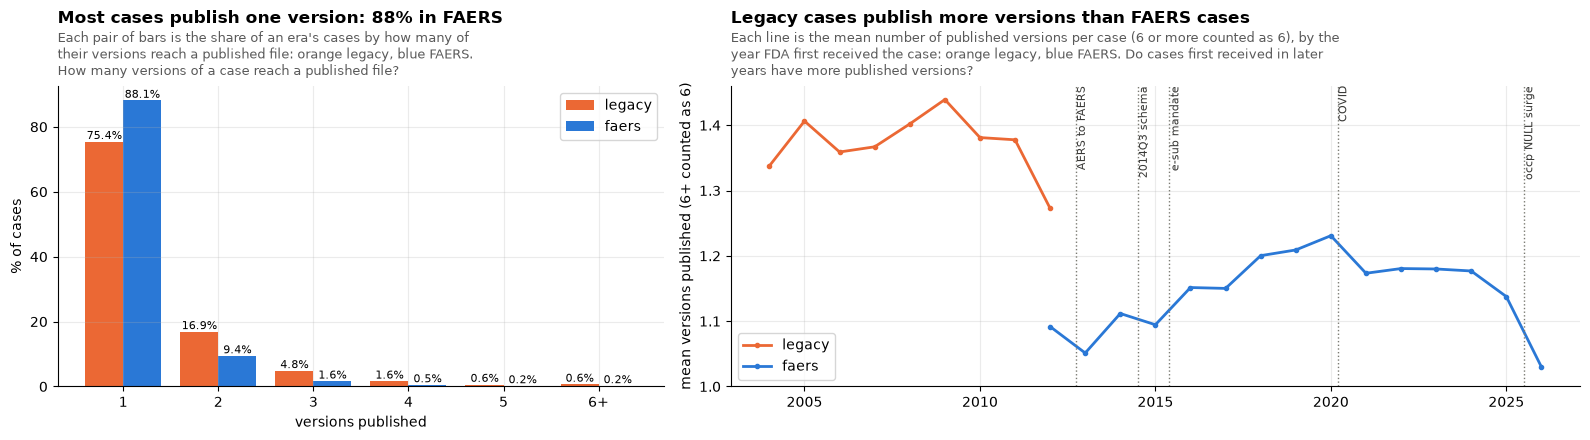

Legacy: 3,091,168 cases; 75.4% have one published version. FAERS: 17,683,864 cases; 88.1% have one published version.


In [2]:
pairs_q = one("""SELECT count(*), count(*) FILTER (WHERE nv > 1) FROM (
                 SELECT count(DISTINCT caseversion) nv FROM demo WHERE era_T = 'faers' GROUP BY caseid, quarter_T)""")
print(
    f"FAERS case-and-quarter pairs: {pairs_q[0]:,}. Pairs holding two versions of the case: {pairs_q[1]:,}. "
    "A quarterly file holds the newest version FDA had at the quarter's end."
)
vp = q("""
WITH l AS (SELECT 'legacy' era, min(fda_year_T) yr, count(DISTINCT primaryid) n FROM demo_T WHERE era_T = 'legacy' GROUP BY case_key_T),
     f AS (SELECT 'faers' era, min(init_year_T) yr, count(DISTINCT caseversion_T) n FROM demo_T WHERE era_T = 'faers' GROUP BY caseid)
SELECT era, yr, least(n, 6) published, count(*) cases FROM (SELECT * FROM l UNION ALL SELECT * FROM f) GROUP BY ALL""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
dist = vp.groupby(["era", "published"]).cases.sum().unstack(0).fillna(0)
share = 100 * dist / dist.sum()
x = np.arange(len(share))
w = 0.4
for i, era in enumerate(["legacy", "faers"]):
    label_bars(a1, a1.bar(x + (i - 0.5) * w, share[era], w, color=ERA[era], label=era), "{:.1f}%")
a1.set_xticks(x)
a1.set_xticklabels([str(int(v)) if v < 6 else "6+" for v in share.index])
a1.set_xlabel("versions published")
a1.set_ylabel("% of cases")
a1.legend()
title(
    a1,
    f"Most cases publish one version: {share.faers[1]:.0f}% in FAERS",
    "Each pair of bars is the share of an era's cases by how many of their versions reach a published file: orange legacy, blue FAERS.",
    "How many versions of a case reach a published file?",
    width=68,
)
by_year = vp.assign(t=vp.published * vp.cases).groupby(["era", "yr"])[["t", "cases"]].sum()
by_year = (by_year.t / by_year.cases).unstack(0)
by_year = by_year[(by_year.index >= 2004) & (by_year.index <= 2026)]
for era in ["legacy", "faers"]:
    s = by_year[era].dropna()
    s = s[s.index >= (2004 if era == "legacy" else 2012)]
    a2.plot(s.index, s.values, color=ERA[era], marker="o", ms=3, label=era)
a2.set_ylim(1, None)
a2.set_ylabel("mean versions published (6+ counted as 6)")
title(
    a2,
    "Legacy cases publish more versions than FAERS cases",
    "Each line is the mean number of published versions per case (6 or more counted as 6), by the year FDA first received the case: "
    "orange legacy, blue FAERS.",
    "Do cases first received in later years have more published versions?",
    width=95,
)
a2.legend()
mark_years(a2)
plt.tight_layout()
plt.show()
tot = vp.groupby("era").cases.sum()
print(
    f"Legacy: {tot.legacy:,} cases; {share.legacy[1]:.1f}% have one published version. "
    f"FAERS: {tot.faers:,} cases; {share.faers[1]:.1f}% have one published version."
)

Most cases are never followed up in a published file. The right end of the FAERS line falls because recent cases have had less time to be followed up, not because senders follow up less.

### How many versions does FDA file but never publish?

In FAERS the version number says how many versions exist, so a gap between the highest version and the versions published is a version FDA filed but never put in a quarterly file: one that a later version replaced before the quarter ended. Cases first received from 2013 (the first full FAERS year), so cases carried over from AERS do not count their AERS versions as missing.

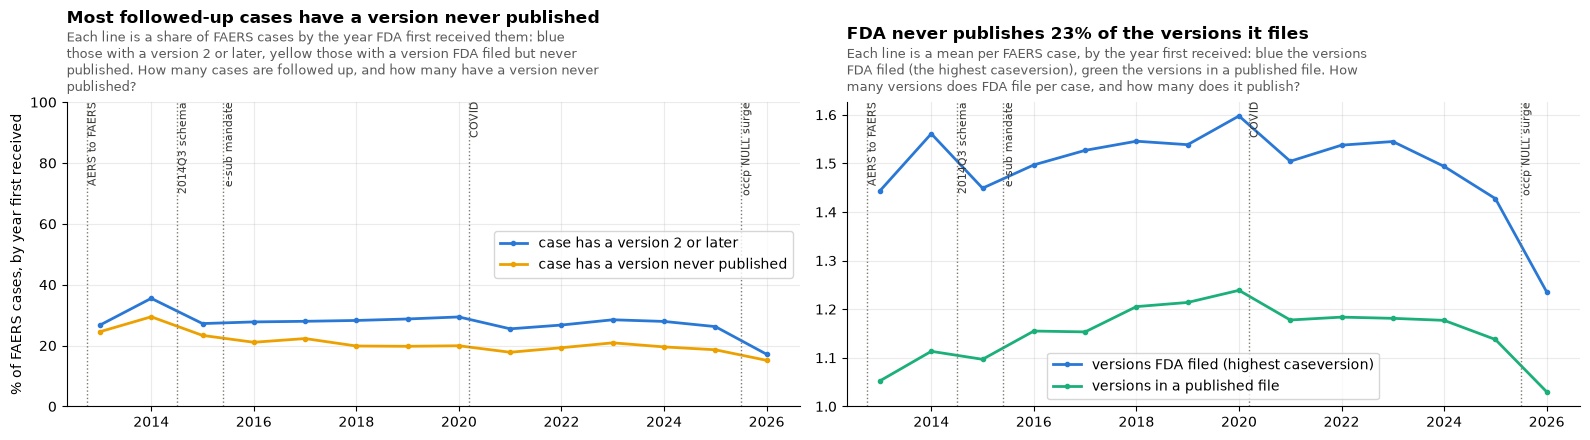

Cases first received 2013 to 2026: 17,351,154. FDA filed 26,112,306 versions of them and never published 5,943,151 (23%), because a later version arrived in the same quarter.


In [3]:
nv = q("""
WITH c AS (SELECT caseid, min(init_year_T) yr, max(caseversion_T) top, count(DISTINCT caseversion_T) pub
           FROM demo_T WHERE era_T = 'faers' GROUP BY caseid)
SELECT yr, count(*) cases, avg(top) mean_versions, avg(pub) mean_published,
       100 * avg((top >= 2)::INT) pct_followed_up, 100 * avg((pub < top)::INT) pct_with_unpublished,
       sum(top - pub) unpublished, sum(top) all_versions
FROM c WHERE yr BETWEEN 2013 AND 2026 GROUP BY 1 ORDER BY 1""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
a1.plot(
    nv.yr,
    nv.pct_followed_up,
    marker="o",
    ms=3,
    color=SERIES[0],
    label="case has a version 2 or later",
)
a1.plot(
    nv.yr,
    nv.pct_with_unpublished,
    marker="o",
    ms=3,
    color=SERIES[3],
    label="case has a version never published",
)
a1.set_ylim(0, 100)
a1.set_ylabel("% of FAERS cases, by year first received")
title(
    a1,
    "Most followed-up cases have a version never published",
    "Each line is a share of FAERS cases by the year FDA first received them: blue those with a version 2 or later, yellow those with a "
    "version FDA filed but never published.",
    "How many cases are followed up, and how many have a version never published?",
    width=81,
)
a1.legend()
mark_years(a1)
a2.plot(
    nv.yr,
    nv.mean_versions,
    marker="o",
    ms=3,
    color=SERIES[0],
    label="versions FDA filed (highest caseversion)",
)
a2.plot(
    nv.yr,
    nv.mean_published,
    marker="o",
    ms=3,
    color=SERIES[2],
    label="versions in a published file",
)
a2.set_ylim(1, None)
title(
    a2,
    f"FDA never publishes {100 * nv.unpublished.sum() / nv.all_versions.sum():.0f}% of the versions it files",
    "Each line is a mean per FAERS case, by the year first received: blue the versions FDA filed (the highest caseversion), green the "
    "versions in a published file.",
    "How many versions does FDA file per case, and how many does it publish?",
    width=81,
)
a2.legend()
mark_years(a2)
plt.tight_layout()
plt.show()
t = nv[["cases", "unpublished", "all_versions"]].sum()
print(
    f"Cases first received 2013 to 2026: {t.cases:,.0f}. FDA filed {t.all_versions:,.0f} versions of them and never published "
    f"{t.unpublished:,.0f} ({100 * t.unpublished / t.all_versions:.0f}%), because a later version arrived in the same quarter."
)

For the funnel this is harmless: the latest version is what counts, and the latest version is always published. It matters for any study of what follow-ups change, because most intermediate versions are not in the files.

### How long after one published version does the next arrive?

Days between one published version of a FAERS case and the next, by FDA receipt date (`fda_dt`).

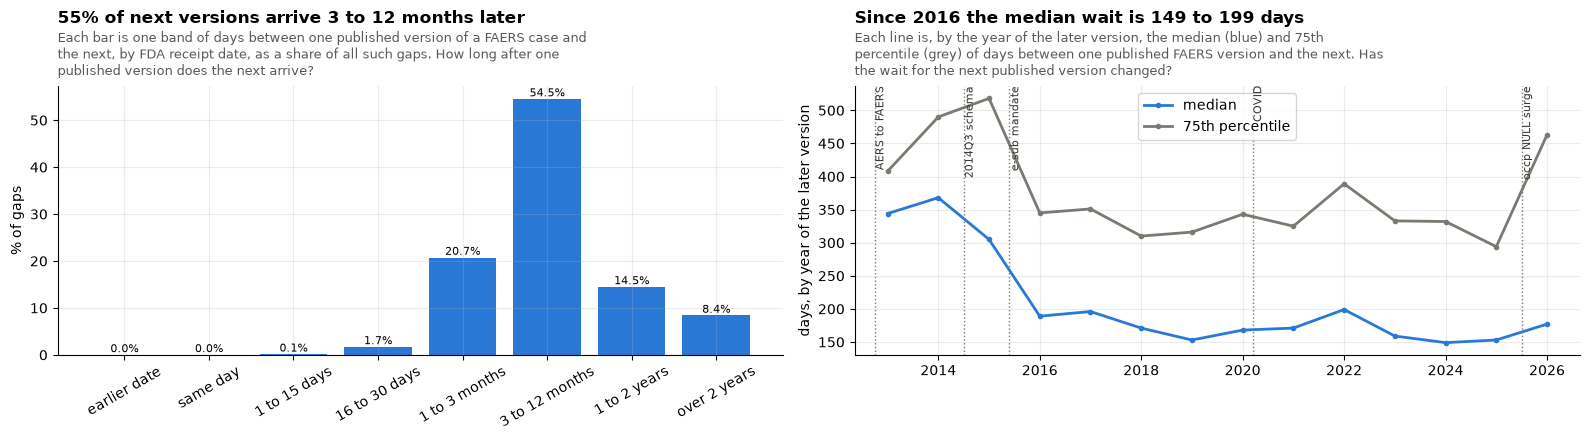

2,851,653 gaps between published versions. Within 30 days: 2%. Over a year: 23%. A later version with an earlier date: 143.


In [4]:
gap_sql = """
WITH v AS (SELECT caseid, caseversion_T, min(fda_dt_T) fda FROM demo_T
           WHERE era_T = 'faers' AND fda_dt_T IS NOT NULL AND caseversion_T IS NOT NULL GROUP BY 1, 2),
     g AS (SELECT fda, fda - lag(fda) OVER (PARTITION BY caseid ORDER BY caseversion_T) AS days FROM v)
SELECT * FROM g WHERE days IS NOT NULL"""
bands = (
    q(f"""
SELECT CASE WHEN days < 0 THEN 'earlier date' WHEN days = 0 THEN 'same day' WHEN days <= 15 THEN '1 to 15 days'
            WHEN days <= 30 THEN '16 to 30 days' WHEN days <= 90 THEN '1 to 3 months' WHEN days <= 365 THEN '3 to 12 months'
            WHEN days <= 730 THEN '1 to 2 years' ELSE 'over 2 years' END band, count(*) n
FROM ({gap_sql}) GROUP BY 1""")
    .set_index("band")
    .reindex(
        [
            "earlier date",
            "same day",
            "1 to 15 days",
            "16 to 30 days",
            "1 to 3 months",
            "3 to 12 months",
            "1 to 2 years",
            "over 2 years",
        ]
    )
    .fillna(0)
)
med = q(
    f"SELECT year(fda) yr, median(days) med, quantile_cont(days, 0.75) p75, count(*) n FROM ({gap_sql}) WHERE days >= 0 GROUP BY 1 ORDER BY 1"
)
med = med[(med.yr >= 2013) & (med.yr <= 2026)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5))
label_bars(a1, a1.bar(bands.index, 100 * bands.n / bands.n.sum(), color=SERIES[0]), "{:.1f}%")
a1.set_ylabel("% of gaps")
a1.tick_params(axis="x", rotation=30)
title(
    a1,
    f"{100 * bands.n['3 to 12 months'] / bands.n.sum():.0f}% of next versions arrive 3 to 12 months later",
    "Each bar is one band of days between one published version of a FAERS case and the next, by FDA receipt date, as a share of all such gaps.",
    "How long after one published version does the next arrive?",
    width=81,
)
a2.plot(med.yr, med.med, marker="o", ms=3, color=SERIES[0], label="median")
a2.plot(med.yr, med.p75, marker="o", ms=3, color=SERIES[6], label="75th percentile")
a2.set_ylabel("days, by year of the later version")
title(
    a2,
    f"Since 2016 the median wait is {med[med.yr >= 2016].med.min():.0f} to {med[med.yr >= 2016].med.max():.0f} days",
    "Each line is, by the year of the later version, the median (blue) and 75th percentile (grey) of days between one published FAERS "
    "version and the next.",
    "Has the wait for the next published version changed?",
    width=81,
)
a2.legend()
mark_years(a2)
plt.tight_layout()
plt.show()
n = bands.n.sum()
print(
    f"{n:,.0f} gaps between published versions. Within 30 days: {100 * bands.n.iloc[1:4].sum() / n:.0f}%. "
    f"Over a year: {100 * bands.n.iloc[6:].sum() / n:.0f}%. A later version with an earlier date: {bands.n.iloc[0]:,.0f}."
)

### Which report numbers were published again in a later quarter?

The same `primaryid` (legacy: ISR) can appear in two quarterly files. FDA's FAQ (question 29) says to use the later record. The latest-version rule already does: the later quarter wins a tie.

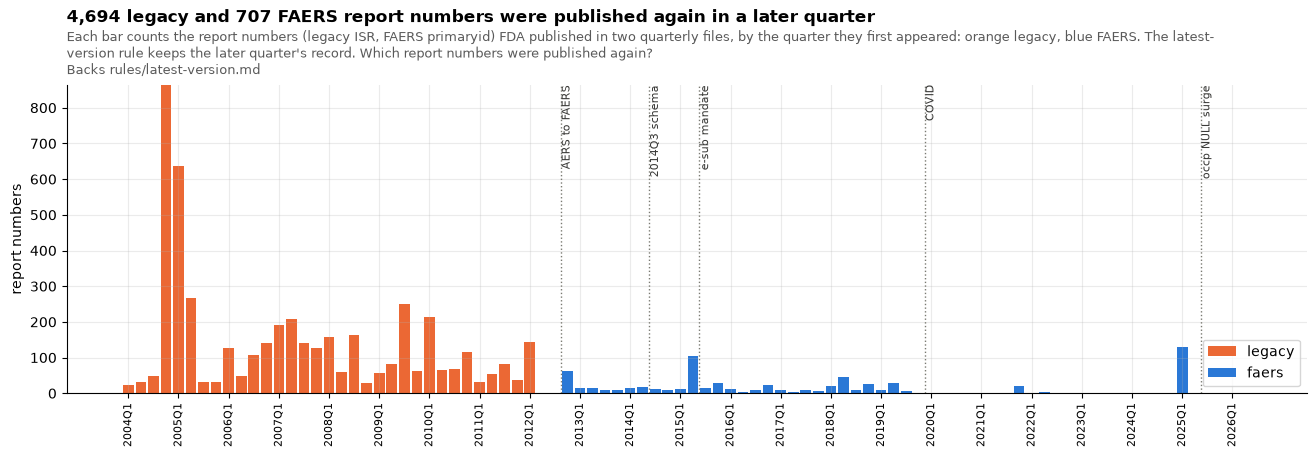

Published again: 4,694 legacy ISRs and 707 FAERS primaryids. Biggest pairs of quarters:


,era_T,first_q,again_q,n
44,legacy,2004q4,2005q1,863
45,legacy,2005q1,2005q2,638
46,legacy,2005q2,2005q3,266
64,legacy,2009q3,2009q4,249
66,legacy,2010q1,2010q2,213
54,legacy,2007q2,2007q3,207


In [5]:
rp = q("""
WITH p AS (SELECT era_T, primaryid, list(DISTINCT quarter_T ORDER BY quarter_T) qs FROM demo GROUP BY 1, 2 HAVING count(DISTINCT quarter_T) > 1)
SELECT era_T, qs[1] first_q, qs[2] again_q, count(*) n FROM p GROUP BY ALL ORDER BY ALL""")
quarters = q("SELECT quarter_T FROM quarters_T ORDER BY qnum_T").quarter_T.tolist()
per_q = (
    rp.pivot_table(index="first_q", columns="era_T", values="n", aggfunc="sum")
    .reindex(quarters)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(16, 4))
bottom = np.zeros(len(per_q))
for era in ["legacy", "faers"]:
    if era in per_q:
        ax.bar(range(len(per_q)), per_q[era], bottom=bottom, color=ERA[era], width=0.85, label=era)
        bottom += per_q[era].values
ax.set_ylabel("report numbers")
again = rp.groupby("era_T").n.sum()
title(
    ax,
    f"{again.get('legacy', 0):,} legacy and {again.get('faers', 0):,} FAERS report numbers were published again in a later quarter",
    "Each bar counts the report numbers (legacy ISR, FAERS primaryid) FDA published in two quarterly files, by the quarter they first "
    "appeared: orange legacy, blue FAERS. The latest-version rule keeps the later quarter's record.",
    "Which report numbers were published again?",
    backs="Backs rules/latest-version.md",
    width=180,
)
quarter_ticks(ax, per_q.index)
mark_quarters(ax, per_q.index)
ax.legend()
plt.show()
tot = rp.groupby("era_T").n.sum()
print(
    f"Published again: {tot.get('legacy', 0):,} legacy ISRs and {tot.get('faers', 0):,} FAERS primaryids. Biggest pairs of quarters:"
)
rp.sort_values("n", ascending=False).head(6)

## 2. Gap A: how can a legacy country name be compared with a FAERS country code?

ISO 3166-1 is the international standard list of countries, each with a two-letter code (`US`, `GB`, `FR`), kept by the International Organization for Standardization. FAERS writes the reporter's country as that code, and from 2012Q4 also the country where the event happened (`occr_country`). Legacy AERS writes the reporter's country as a name in capitals (`UNITED STATES`). The duplicate key compared the raw text, so a legacy case could never match a FAERS case, and the explorer's country filter found only one era's cases for any country.

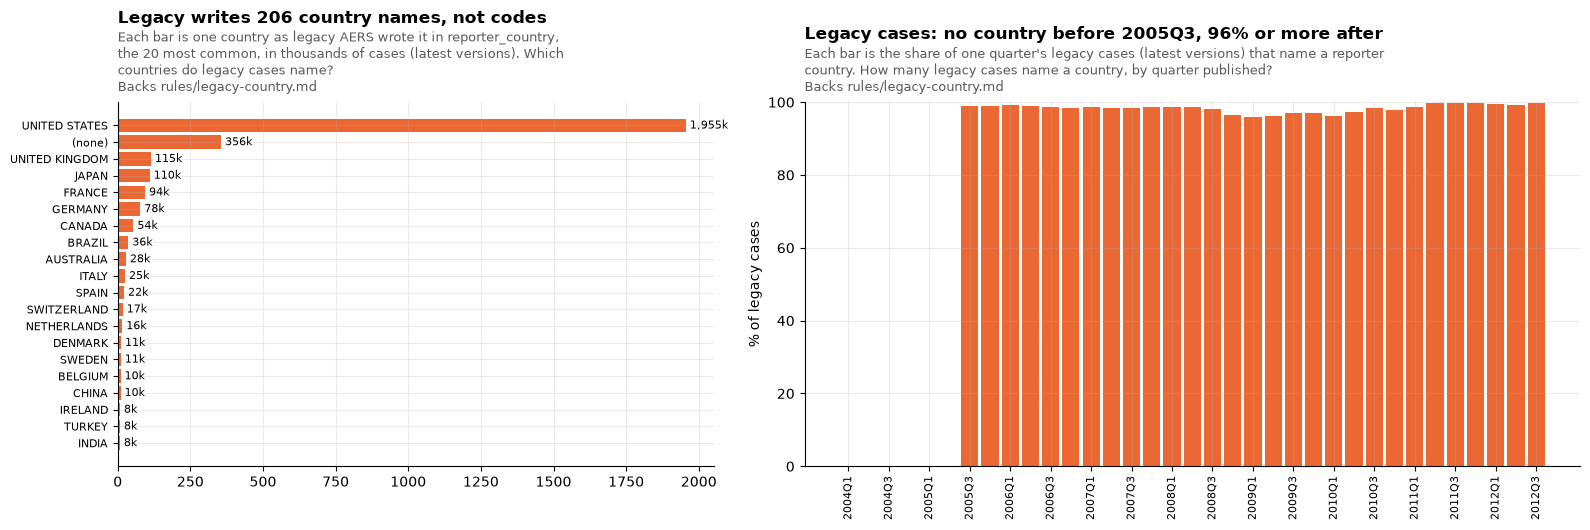

Legacy uses 206 distinct country names; 355,848 legacy cases have none (the 2004Q1 layout has no country column until 2005Q3).


In [6]:
lc = q(
    "SELECT coalesce(reporter_country, '(none)') AS country, count(*) AS n FROM case_latest_T WHERE era_T = 'legacy' GROUP BY 1 ORDER BY 2 DESC"
)
cov = q(
    "SELECT quarter_T, 100 * avg((reporter_country IS NOT NULL)::INT) pct FROM case_latest_T WHERE era_T = 'legacy' GROUP BY 1 ORDER BY 1"
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1, 1.3]})
top = lc.head(20)
label_bars(
    a1, a1.barh(top.country[::-1], top.n[::-1] / 1e3, color=SERIES[1]), "{:,.0f}k", horizontal=True
)
title(
    a1,
    f"Legacy writes {len(lc) - 1} country names, not codes",
    "Each bar is one country as legacy AERS wrote it in reporter_country, the 20 most common, in thousands of cases (latest versions).",
    "Which countries do legacy cases name?",
    backs="Backs rules/legacy-country.md",
    width=70,
)
a1.tick_params(axis="y", labelsize=8)
a2.bar(range(len(cov)), cov.pct, color=SERIES[1], width=0.85)
quarter_ticks(a2, cov.quarter_T, every=2)
a2.set_ylim(0, 100)
a2.set_ylabel("% of legacy cases")
title(
    a2,
    f"Legacy cases: no country before 2005Q3, {int(cov[cov.quarter_T >= '2005q3'].pct.min())}% or more after",
    "Each bar is the share of one quarter's legacy cases (latest versions) that name a reporter country.",
    "How many legacy cases name a country, by quarter published?",
    backs="Backs rules/legacy-country.md",
    width=92,
)
plt.tight_layout()
plt.show()
print(
    f"Legacy uses {len(lc) - 1} distinct country names; {lc.set_index('country').n.get('(none)', 0):,} legacy cases have none "
    f"(the 2004Q1 layout has no country column until 2005Q3)."
)

### The mapping, and FDA's own answer key

`mappings/faers/countries/accepted.csv` gives each of the 208 names legacy AERS ever used its two-letter code. 176 are written exactly as the ISO list names the country. The other 32 were checked by hand: 20 are older official names (`UNITED STATES` for what the list now calls "United States of America", `KOREA, REPUBLIC OF`), 4 are names without their accents (`REUNION`), 4 are two names each for `AN` (Netherlands Antilles) and `CS` (Serbia and Montenegro), and one each is for `EU`, `FX`, `YU` and `CD` (`ZAIRE`). So 208 names give 205 codes. AEOLUS maps legacy names to codes too, with the same 32 hand-added names; ours differ from it in two, `European Union` as `EU` and `FRANCE, METROPOLITAN` as `FX`, the codes FAERS itself uses.

The check uses an answer key FDA made. In 2012 FDA carried many AERS cases into FAERS under the same case number (section 3), and FDA itself chose the code each one's country got in FAERS. So for every carried-over case we can compare our code for the legacy name with FDA's. In the left chart:

- **green**: FDA's FAERS version has the code we map the name to;
- **grey**: FDA's FAERS version says `COUNTRY NOT SPECIFIED` instead of a code;
- **orange**: FDA's FAERS version has another code.

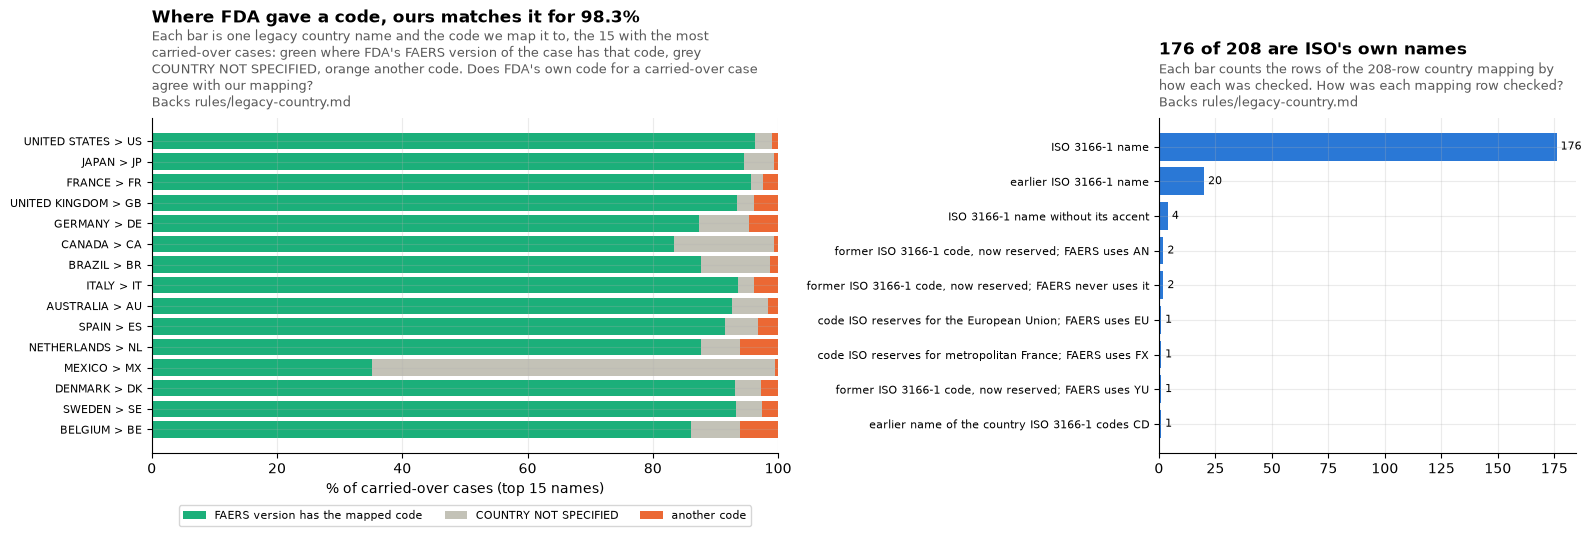

Carried-over cases with a legacy country: 81,604. Where the FAERS version names a country, it is the mapped code for 98.3%; 3,832 say COUNTRY NOT SPECIFIED.
Of those 3,832, 3,668 (96%) give an event country (occr_country) equal to our code.
FAERS cases whose reporter_country is the text COUNTRY NOT SPECIFIED: 690,445.
Mexico: 571 carried-over cases; the largest group is one sender's reports published in 2013: 379, of which 295 say COUNTRY NOT SPECIFIED and 379 give MX as the event country.


,fda_value,iso2,evidence
1,ALAND ISLANDS,AX,ISO 3166-1 name without its accent
24,BOLIVIA,BO,earlier ISO 3166-1 name
25,BOSNIA AND HERZEGOWINA,BA,earlier ISO 3166-1 name
35,CAPE VERDE,CV,earlier ISO 3166-1 name
41,"CONGO, THE DEMOCRATIC REPUBLIC OF THE",CD,earlier ISO 3166-1 name
43,COTE D'IVOIRE,CI,ISO 3166-1 name without its accent
44,CROATIA (local name: Hrvatska),HR,earlier ISO 3166-1 name
46,CURACAO,CW,ISO 3166-1 name without its accent
57,European Union,EU,code ISO reserves for the European Union; FAERS uses EU
62,"FRANCE, METROPOLITAN",FX,code ISO reserves for metropolitan France; FAERS uses FX


In [7]:
cmap = pd.read_csv(
    MAPPING, dtype=str, keep_default_na=False
)  # 'NA' is Namibia, not a missing value
con.register("cmap_df", cmap)
con.execute("""
CREATE OR REPLACE TEMP TABLE carried_country_T AS
WITH l AS (SELECT caseid, reporter_country lc FROM demo_latest_T WHERE era_T = 'legacy' AND reporter_country IS NOT NULL),
     f AS (SELECT caseid, reporter_country fc, occr_country fo, mfr_sndr, quarter_T fq FROM demo_latest_T WHERE era_T = 'faers')
SELECT l.caseid, l.lc AS country, m.iso2, f.fc, f.fo, f.mfr_sndr, f.fq FROM l JOIN f USING (caseid) JOIN cmap_df m ON m.fda_value = l.lc""")
chk = q("""SELECT country, iso2, count(*) FILTER (WHERE fc = iso2) same_code,
                  count(*) FILTER (WHERE fc = 'COUNTRY NOT SPECIFIED') not_specified,
                  count(*) FILTER (WHERE fc <> iso2 AND fc <> 'COUNTRY NOT SPECIFIED') other_code
           FROM carried_country_T GROUP BY 1, 2""")
chk["n"] = chk[["same_code", "not_specified", "other_code"]].sum(axis=1)
top = chk.sort_values("n", ascending=False).head(15).iloc[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.5, 1]})
left = np.zeros(len(top))
for col, color, label in [
    ("same_code", SERIES[2], "FAERS version has the mapped code"),
    ("not_specified", SERIES[7], "COUNTRY NOT SPECIFIED"),
    ("other_code", SERIES[1], "another code"),
]:
    a1.barh(
        top.country + " > " + top.iso2, 100 * top[col] / top.n, left=left, color=color, label=label
    )
    left += (100 * top[col] / top.n).values
a1.set_xlim(0, 100)
a1.set_xlabel("% of carried-over cases (top 15 names)")
key_ = chk[["same_code", "other_code"]].sum()
title(
    a1,
    f"Where FDA gave a code, ours matches it for {100 * key_.same_code / key_.sum():.1f}%",
    "Each bar is one legacy country name and the code we map it to, the 15 with the most carried-over cases: green where FDA's FAERS "
    "version of the case has that code, grey COUNTRY NOT SPECIFIED, orange another code.",
    "Does FDA's own code for a carried-over case agree with our mapping?",
    backs="Backs rules/legacy-country.md",
    width=90,
)
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8)
a1.tick_params(axis="y", labelsize=8)
ev = cmap.evidence.value_counts()
label_bars(a2, a2.barh(ev.index[::-1], ev.values[::-1], color=SERIES[0]), horizontal=True)
title(
    a2,
    f"{ev.get('ISO 3166-1 name', 0)} of {len(cmap)} are ISO's own names",
    f"Each bar counts the rows of the {len(cmap)}-row country mapping by how each was checked.",
    "How was each mapping row checked?",
    backs="Backs rules/legacy-country.md",
    width=61,
)
a2.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
s = chk[["same_code", "not_specified", "other_code"]].sum()
ns = one(
    "SELECT count(*), count(*) FILTER (WHERE fo = iso2) FROM carried_country_T WHERE fc = 'COUNTRY NOT SPECIFIED'"
)
cns = one(
    "SELECT count(*) FROM case_latest_T WHERE era_T = 'faers' AND reporter_country = 'COUNTRY NOT SPECIFIED'"
)[0]
mx = q("""SELECT mfr_sndr, left(fq, 4) yr, count(*) n, count(*) FILTER (WHERE fo = 'MX') occr_mx,
                 count(*) FILTER (WHERE fc = 'COUNTRY NOT SPECIFIED') not_specified
          FROM carried_country_T WHERE country = 'MEXICO' GROUP BY ALL ORDER BY n DESC""")
print(
    f"Carried-over cases with a legacy country: {s.sum():,}. Where the FAERS version names a country, it is the mapped code for "
    f"{100 * s.same_code / (s.same_code + s.other_code):.1f}%; {s.not_specified:,} say COUNTRY NOT SPECIFIED."
)
print(
    f"Of those {ns[0]:,}, {ns[1]:,} ({100 * ns[1] / ns[0]:.0f}%) give an event country (occr_country) equal to our code."
)
print(f"FAERS cases whose reporter_country is the text COUNTRY NOT SPECIFIED: {cns:,}.")
print(
    f"Mexico: {mx.n.sum():,} carried-over cases; the largest group is one sender's reports published in {mx.yr[0]}: "
    f"{mx.n[0]:,}, of which {mx.not_specified[0]:,} say COUNTRY NOT SPECIFIED and {mx.occr_mx[0]:,} give MX as the event country."
)
cmap[cmap.evidence != "ISO 3166-1 name"]

**What the colours show.** Where FDA gave the carried-over case a code, it is almost always ours. The grey is not a disagreement: `COUNTRY NOT SPECIFIED` is literal FDA text, written in FAERS's `reporter_country` where the reporter gave no country (FAQ 21), on 690,445 FAERS cases. For the carried-over cases that say it, the event country (`occr_country`) equals our code in 96%. The Mexico bar is mostly one sender's reports published in 2013: 379 of the 571 carried Mexican cases, 295 of them saying `COUNTRY NOT SPECIFIED`, and every one with `MX` as its event country.

**Serbia and Montenegro.** Two codes never appear in FAERS: `CS` and `SJ` (Svalbard and Jan Mayen, one case). `CS` was Czechoslovakia's code until 1993; ISO gave it to Serbia and Montenegro in 2003 and withdrew it after the country split in June 2006. 35 legacy cases name Serbia and Montenegro. They were received from 2006 to 2011, 31 of them after the split. They stay `CS`, as reported; reading them as Serbia would be a guess. They can match each other, never a FAERS case.

### What the mapping changes

Every legacy case with a country gets a code: none is left unmapped (the build refuses a name the mapping lacks). Counted here from the release before the fix, with gap B fixed first, as the pipeline does, so a case carried into FAERS is not matched against its own AERS copy. The example group is the duplicate key shown at the top of the notebook, read from the release after.

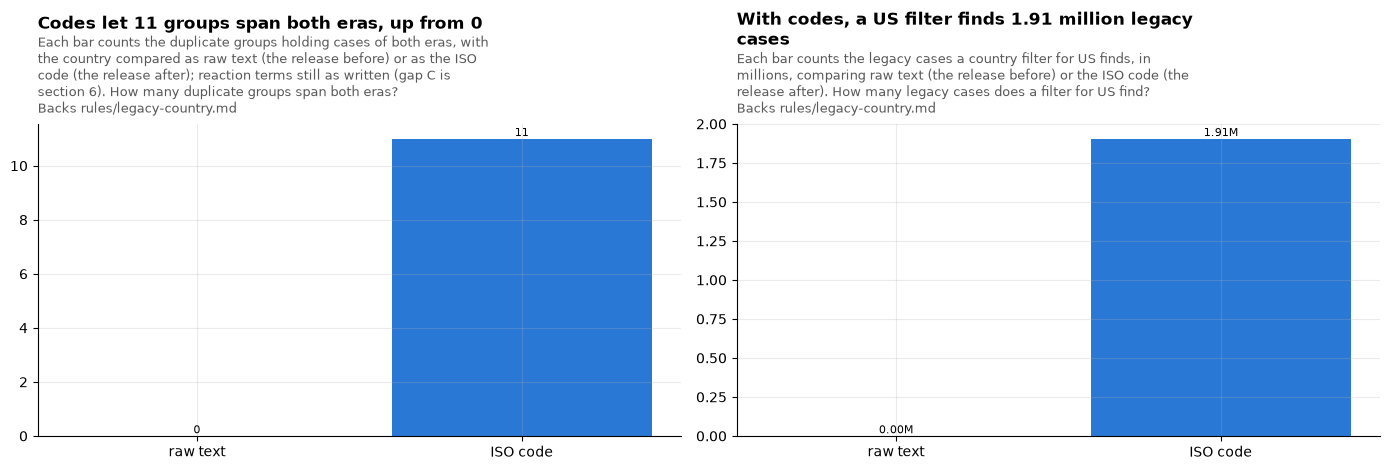

Legacy cases with a country left without a code: 0. Duplicate groups spanning both eras: 0 as raw text, 11 with codes. A filter for US finds 1,905,215 legacy cases, none as raw text.
Legacy cases read as CS (Serbia and Montenegro): 35, received 2006-02-24 to 2011-12-01, 31 of them after the split on 3 June 2006.


,dup_key_T,era_T,case_key_T,reporter_country,occr_country,received,kept
0,20081019|68|YR|M|GB|ACYCLOVIR|LOSARTAN POTASSIUM|DYSPHAGIA|ODYNOPHAGIA,legacy,6963675,UNITED KINGDOM,None,2009-04-08,True
1,20081019|68|YR|M|GB|ACYCLOVIR|LOSARTAN POTASSIUM|DYSPHAGIA|ODYNOPHAGIA,faers,6992076,GB,None,2009-04-27,False


In [8]:
con.execute("""
CREATE OR REPLACE TEMP TABLE grain_T AS
SELECT c.era_T, c.case_key_T, c.caseid, c.primaryid, c.quarter_T, c.first_fda_dt_T, c.mfr_num, c.mfr_sndr, k.dup_key_T,
       CASE WHEN upper(c.sex) IN ('F', 'M') THEN upper(c.sex) END AS sex_mf_T,
       c.era_T = 'legacy' AND coalesce(c.caseid IN (SELECT caseid FROM demo_latest_T WHERE era_T = 'faers'), false) AS carried_T,
       c.era_T = 'legacy' AND coalesce(c.caseid IN (SELECT caseid FROM deleted_cases_T), false) AS legacy_listed_T,
       CASE WHEN c.era_T = 'legacy' THEN m.iso2 ELSE coalesce(c.occr_country, c.reporter_country) END AS country_T,
       CASE WHEN c.era_T = 'legacy' THEN m.iso2 ELSE c.reporter_country END AS reporter_code_T,
       CASE WHEN c.era_T = 'legacy' AND k.dup_key_T IS NOT NULL
            THEN concat_ws('|', c.event_dt, c.age, c.age_cod, c.sex, m.iso2)
                 || substr(k.dup_key_T, length(concat_ws('|', c.event_dt, c.age, c.age_cod, c.sex, c.reporter_country)) + 1)
            ELSE k.dup_key_T END AS iso_key_T
FROM case_latest_T c JOIN case_dup_T k USING (era_T, case_key_T)
LEFT JOIN cmap_df m ON c.era_T = 'legacy' AND m.fda_value = c.reporter_country""")
# the reconstruction must give back the release's own key exactly where the raw name is kept
assert (
    one(
        "SELECT count(*) FROM grain_T WHERE era_T = 'legacy' AND dup_key_T IS NOT NULL AND iso_key_T IS NULL"
    )[0]
    == 0
)
r = q("""
WITH g AS (SELECT * FROM grain_T WHERE NOT carried_T)
SELECT 'raw text' how, (SELECT count(*) FROM (SELECT dup_key_T FROM g WHERE dup_key_T IS NOT NULL GROUP BY 1 HAVING count(DISTINCT era_T) > 1)) groups_both_eras,
       (SELECT count(*) FROM case_latest_T WHERE era_T = 'legacy' AND coalesce(occr_country, reporter_country) = 'US') legacy_found_by_US
UNION ALL
SELECT 'ISO code', (SELECT count(*) FROM (SELECT iso_key_T FROM g WHERE iso_key_T IS NOT NULL GROUP BY 1 HAVING count(DISTINCT era_T) > 1)),
       (SELECT count(*) FROM g WHERE era_T = 'legacy' AND country_T = 'US')""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
label_bars(a1, a1.bar(r.how, r.groups_both_eras, color=[SERIES[6], SERIES[0]]))
title(
    a1,
    f"Codes let {r.groups_both_eras[1]} groups span both eras, up from {r.groups_both_eras[0]}",
    "Each bar counts the duplicate groups holding cases of both eras, with the country compared as raw text (the release before) or "
    "as the ISO code (the release after); reaction terms still as written (gap C is section 6).",
    "How many duplicate groups span both eras?",
    backs="Backs rules/legacy-country.md",
    width=71,
)
label_bars(a2, a2.bar(r.how, r.legacy_found_by_US / 1e6, color=[SERIES[6], SERIES[0]]), "{:.2f}M")
title(
    a2,
    f"With codes, a US filter finds {r.legacy_found_by_US[1] / 1e6:.2f} million legacy cases",
    "Each bar counts the legacy cases a country filter for US finds, in millions, comparing raw text (the release before) or the "
    "ISO code (the release after).",
    "How many legacy cases does a filter for US find?",
    backs="Backs rules/legacy-country.md",
    width=71,
)
plt.tight_layout()
plt.show()
unmapped = one(
    "SELECT count(*) FROM grain_T g JOIN case_latest_T c USING (era_T, case_key_T) WHERE g.era_T = 'legacy' AND g.country_T IS NULL AND c.reporter_country IS NOT NULL"
)[0]
print(
    f"Legacy cases with a country left without a code: {unmapped}. Duplicate groups spanning both eras: {r.groups_both_eras[0]} as raw text, "
    f"{r.groups_both_eras[1]} with codes. A filter for US finds {r.legacy_found_by_US[1]:,} legacy cases, none as raw text."
)
cs = one("""SELECT count(*), min(first_fda_dt_T), max(first_fda_dt_T), count(*) FILTER (WHERE first_fda_dt_T >= DATE '2006-06-03')
             FROM grain_T WHERE NOT carried_T AND country_T = 'CS'""")
print(
    f"Legacy cases read as CS (Serbia and Montenegro): {cs[0]}, received {cs[1]} to {cs[2]}, {cs[3]} of them after the split on 3 June 2006."
)
EXAMPLE = "20081019|68|YR|M|GB|ACYCLOVIR|LOSARTAN POTASSIUM|DYSPHAGIA|ODYNOPHAGIA"
acon.execute(f"""SELECT k.dup_key_T, c.era_T, c.case_key_T, c.reporter_country, c.occr_country, c.first_fda_dt_T AS received, c.dup_kept_T AS kept
                 FROM case_dup_T k JOIN case_latest_T c USING (era_T, case_key_T) WHERE k.dup_key_T = '{EXAMPLE}' ORDER BY c.first_fda_dt_T""").fetchdf()

The country fix alone changes few duplicate flags, because legacy reaction terms are in capitals and FAERS's are not; section 6 fixes that (gap C). Its larger effect here is on filters: one country choice now finds both eras.

### Which country should the key use: the event's or the reporter's?

FAERS has two country fields: where the reporter is (`reporter_country`) and, from 2012Q4, where the event happened (`occr_country`). The pipeline uses the event country and falls back to the reporter's. AEOLUS uses the reporter's only. Both are measured below with gaps A, B and C fixed, before the deleted AERS cases are removed (section 7 adds that). To compare reaction terms in capitals from the release before the fix, each case's set of terms is replaced by a fingerprint: the XOR of the MD5 hashes of its distinct terms. Section 6 checks that the fingerprint gives back the same groups as the terms themselves.

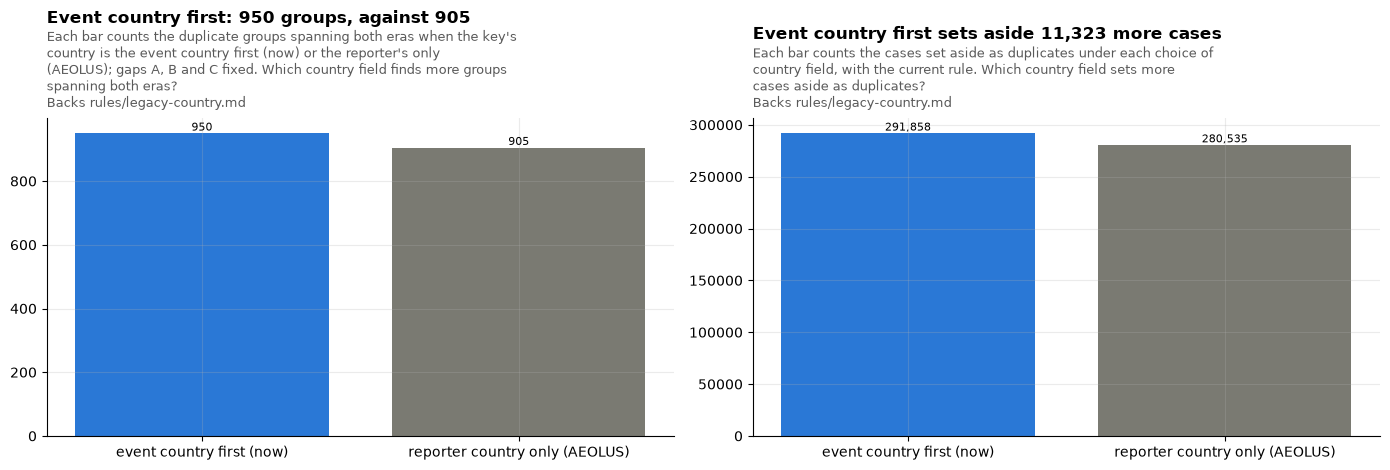

Groups spanning both eras: 950 with the event country first, 905 with the reporter's only. Cases set aside: 291,858 against 280,535.
In the release after, 0 cases have no event country and COUNTRY NOT SPECIFIED as the reporter's, so that text is their country in the key; 0 of them are set aside as duplicates.


,groups_across_eras,set_aside_current_rule,set_aside_with_mfr_num
event country first (now),950,291858,295930
reporter country only (AEOLUS),905,280535,284607


In [9]:
assert (
    one("SELECT count(*) FROM reac_latest_T WHERE contains(pt, '|')")[0] == 0
)  # a term never holds the key's separator
con.execute(
    "CREATE OR REPLACE TEMP TABLE pt_sets_T (era_T VARCHAR, primaryid VARCHAR, quarter_T VARCHAR, n_T BIGINT, as_written_T UHUGEINT, in_caps_T UHUGEINT)"
)
for (qq,) in con.execute(
    "SELECT quarter_T FROM quarters_T ORDER BY qnum_T"
).fetchall():  # a quarter at a time, to stay small
    con.execute(f"""INSERT INTO pt_sets_T SELECT era_T, primaryid, quarter_T, count(DISTINCT pt),
                    bit_xor(DISTINCT md5_number(pt)), bit_xor(DISTINCT md5_number(upper(pt)))
                    FROM reac_latest_T WHERE pt IS NOT NULL AND quarter_T = '{qq}' GROUP BY ALL""")
PARTS = "string_split(g.iso_key_T, '|')"
DRUGS = f"list_slice({PARTS}, 6, len({PARTS}) - p.n_T)"  # the key's drug names: after the five single fields, before the terms
STEM = (
    f"array_to_string(list_slice({PARTS}, 1, len({PARTS}) - p.n_T), '|')"  # the key less its terms
)
REP_STEM = f"array_to_string(list_concat(list_slice({PARTS}, 1, 4), [g.reporter_code_T], {DRUGS}), '|')"  # reporter country in 5th place
con.execute(f"""
CREATE OR REPLACE TEMP TABLE grain_T AS
SELECT g.*,
       CASE WHEN g.iso_key_T IS NOT NULL THEN md5_number({STEM} || '|' || p.as_written_T::VARCHAR) END AS written_key_T,
       CASE WHEN g.iso_key_T IS NOT NULL THEN md5_number({STEM} || '|' || p.in_caps_T::VARCHAR) END AS up_key_T,
       CASE WHEN g.iso_key_T IS NOT NULL AND g.reporter_code_T IS NOT NULL
            THEN md5_number({REP_STEM} || '|' || p.in_caps_T::VARCHAR) END AS rep_key_T
FROM grain_T g LEFT JOIN pt_sets_T p ON p.era_T = g.era_T AND p.primaryid = g.primaryid AND p.quarter_T = g.quarter_T""")


def dup_counts(c, table, key):
    """Groups spanning both eras, and cases set aside: by the current rule, and by it or the manufacturer number."""
    return (
        c.execute(f"""
    WITH r AS (SELECT era_T, {key} AS k,
                 {key} IS NOT NULL AND row_number() OVER (PARTITION BY {key} ORDER BY {ORD}) > 1 AS aside_cur,
                 mfr_num IS NOT NULL AND mfr_sndr IS NOT NULL AND row_number() OVER (PARTITION BY mfr_num, mfr_sndr ORDER BY {ORD}) > 1 AS aside_mfr,
                 count(DISTINCT sex_mf_T) OVER (PARTITION BY mfr_num, mfr_sndr) > 1 AS two_sexes FROM {table})
    SELECT (SELECT count(*) FROM (SELECT k FROM r WHERE k IS NOT NULL GROUP BY 1 HAVING count(DISTINCT era_T) = 2)) AS groups_across_eras,
           count(*) FILTER (WHERE aside_cur) AS set_aside_current_rule,
           count(*) FILTER (WHERE aside_cur OR (aside_mfr AND NOT two_sexes)) AS set_aside_with_mfr_num
    FROM r""")
        .fetchdf()
        .iloc[0]
    )


NOT_CARRIED = "(SELECT * FROM grain_T WHERE NOT carried_T)"
cc = pd.DataFrame(
    {
        "event country first (now)": dup_counts(con, NOT_CARRIED, "up_key_T"),
        "reporter country only (AEOLUS)": dup_counts(con, NOT_CARRIED, "rep_key_T"),
    }
).T.astype(int)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
label_bars(a1, a1.bar(cc.index, cc.groups_across_eras, color=[SERIES[0], SERIES[6]]))
title(
    a1,
    f"Event country first: {cc.groups_across_eras.iloc[0]:,} groups, against {cc.groups_across_eras.iloc[1]:,}",
    "Each bar counts the duplicate groups spanning both eras when the key's country is the event country first (now) or the reporter's "
    "only (AEOLUS); gaps A, B and C fixed.",
    "Which country field finds more groups spanning both eras?",
    backs="Backs rules/legacy-country.md",
    width=71,
)
label_bars(a2, a2.bar(cc.index, cc.set_aside_current_rule, color=[SERIES[0], SERIES[6]]))
title(
    a2,
    f"Event country first sets aside {cc.set_aside_current_rule.iloc[0] - cc.set_aside_current_rule.iloc[1]:,} more cases",
    "Each bar counts the cases set aside as duplicates under each choice of country field, with the current rule.",
    "Which country field sets more cases aside as duplicates?",
    backs="Backs rules/legacy-country.md",
    width=71,
)
plt.tight_layout()
plt.show()
cns_key = acon.execute(
    "SELECT count(*), count(*) FILTER (WHERE NOT dup_kept_T) FROM case_latest_T WHERE country_T = 'COUNTRY NOT SPECIFIED'"
).fetchone()
print(
    f"Groups spanning both eras: {cc.groups_across_eras.iloc[0]:,} with the event country first, {cc.groups_across_eras.iloc[1]:,} with the reporter's only. "
    f"Cases set aside: {cc.set_aside_current_rule.iloc[0]:,} against {cc.set_aside_current_rule.iloc[1]:,}."
)
print(
    f"In the release after, {cns_key[0]:,} cases have no event country and COUNTRY NOT SPECIFIED as the reporter's, "
    f"so that text is their country in the key; {cns_key[1]:,} of them are set aside as duplicates."
)
cc

The event country first finds more: 950 groups spanning both eras against 905, and 291,990 cases set aside against 280,668. The reason is the text `COUNTRY NOT SPECIFIED`. FAERS writes it in `reporter_country` on 690,445 cases, many of which do give an event country; with the reporter's country only, those cases can match only each other. The pipeline keeps the event country first.

## 3. Gap B: are the case numbers counted in both eras one case each?

The release before chose the latest version per era, so a case with versions in both AERS and FAERS was counted twice: 82,342 case numbers in `demo_latest_T`, 82,112 in `case_latest_T` (230 have their FAERS version on a deleted list, but their AERS copy stayed). First: are they the same case?

### Do the AERS and FAERS versions of one case number describe the same case?

For each of these case numbers, the latest AERS version is compared with the latest FAERS version. **The control** is what makes the comparison safe to trust: each AERS version is also compared with the FAERS version of a *different* carried-over case, half the set away in case-number order, so another case from the same migration, received at another time. If FDA had reused case numbers for unrelated cases, the real pairs would agree about as little as the control does. Each field counts only the pairs where both versions give it.

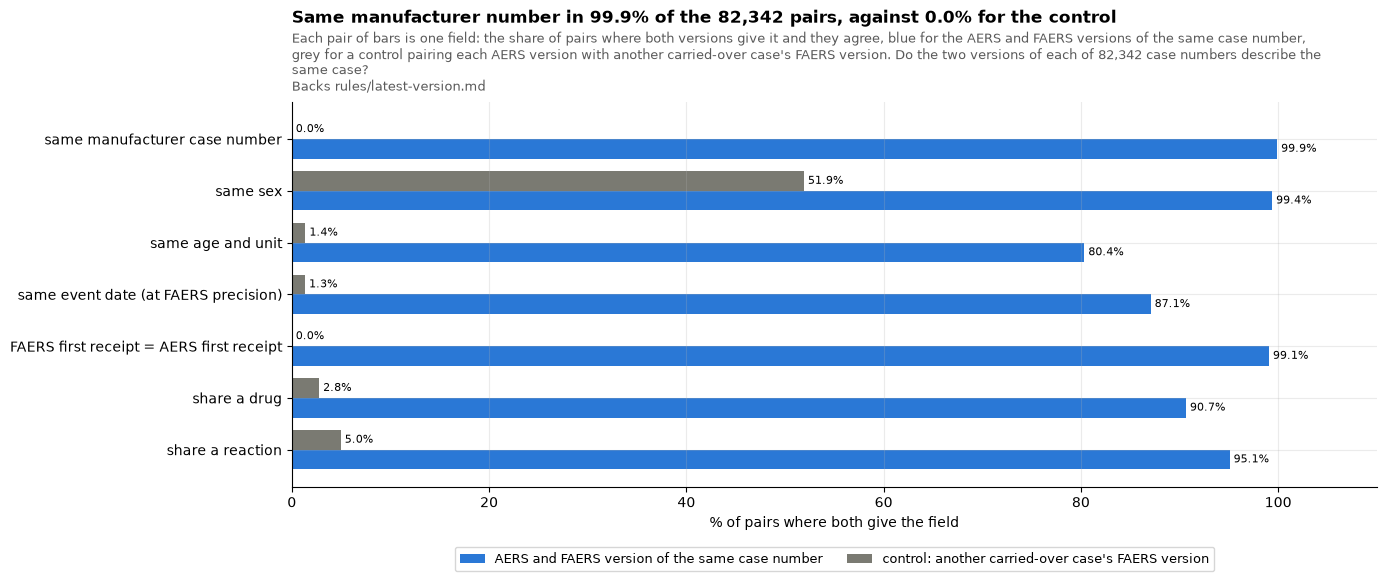

,same case number,control: another carried-over case
same manufacturer case number,99.9,0.0
same sex,99.4,51.9
same age and unit,80.4,1.4
same event date (at FAERS precision),87.1,1.3
FAERS first receipt = AERS first receipt,99.1,0.0
share a drug,90.7,2.8
share a reaction,95.1,5.0


In [10]:
con.execute("""
CREATE OR REPLACE TEMP TABLE pairs_T AS
WITH l AS (SELECT * FROM demo_latest_T WHERE era_T = 'legacy' AND caseid IS NOT NULL),
     f AS (SELECT * FROM demo_latest_T WHERE era_T = 'faers'),
     first_legacy AS (SELECT caseid, min(fda_dt) first_fda, count(DISTINCT primaryid) n_legacy FROM demo WHERE era_T = 'legacy' GROUP BY 1),
     first_faers AS (SELECT caseid, arg_min(quarter_T, caseversion_T::BIGINT * 100000 + qnum_T) first_q,
                            arg_min(fda_dt, caseversion_T::BIGINT * 100000 + qnum_T) first_f_fda, min(caseversion_T) first_cv
                     FROM demo_T WHERE era_T = 'faers' GROUP BY 1)
SELECT l.caseid, l.primaryid lp, l.quarter_T lq, l.fda_dt l_fda, l.event_dt l_event, l.age l_age, l.age_cod l_age_cod, l.sex l_sex, l.mfr_num l_mfr, l.reporter_country l_country,
       f.primaryid fp, f.quarter_T fq, f.fda_dt f_fda, f.init_fda_dt f_init, f.event_dt f_event, f.age f_age, f.age_cod f_age_cod, f.sex f_sex, f.mfr_num f_mfr, f.reporter_country f_country, f.caseversion_T f_cv,
       fl.first_fda, fl.n_legacy, ff.first_cv, ff.first_q, ff.first_f_fda,
       row_number() OVER (ORDER BY l.caseid) i
FROM l JOIN f USING (caseid) JOIN first_legacy fl USING (caseid) JOIN first_faers ff USING (caseid)""")
con.execute("""
CREATE OR REPLACE TEMP TABLE sets_T AS
SELECT p.i, 'legacy' side, list(DISTINCT d.drugname_norm_T) drugs, NULL::VARCHAR[] pts FROM pairs_T p JOIN drug_latest_T d ON d.era_T = 'legacy' AND d.primaryid = p.lp AND d.quarter_T = p.lq GROUP BY 1
UNION ALL SELECT p.i, 'faers', list(DISTINCT d.drugname_norm_T), NULL FROM pairs_T p JOIN drug_latest_T d ON d.era_T = 'faers' AND d.primaryid = p.fp AND d.quarter_T = p.fq GROUP BY 1
UNION ALL SELECT p.i, 'legacy_pt', NULL, list(DISTINCT lower(r.pt)) FROM pairs_T p JOIN reac_latest_T r ON r.era_T = 'legacy' AND r.primaryid = p.lp AND r.quarter_T = p.lq GROUP BY 1
UNION ALL SELECT p.i, 'faers_pt', NULL, list(DISTINCT lower(r.pt)) FROM pairs_T p JOIN reac_latest_T r ON r.era_T = 'faers' AND r.primaryid = p.fp AND r.quarter_T = p.fq GROUP BY 1""")
N = one("SELECT count(*) FROM pairs_T")[0]


def agreement(shift):
    # shift 0: a case against its own FAERS version; otherwise against another carried-over case's
    return q(f"""
    WITH a AS (SELECT * FROM pairs_T), b AS (SELECT * FROM pairs_T)
    SELECT
      100 * avg(CASE WHEN a.l_mfr IS NOT NULL AND b.f_mfr IS NOT NULL THEN (upper(a.l_mfr) = upper(b.f_mfr))::INT END) "same manufacturer case number",
      100 * avg(CASE WHEN a.l_sex IS NOT NULL AND b.f_sex IS NOT NULL THEN (a.l_sex = b.f_sex)::INT END) "same sex",
      100 * avg(CASE WHEN a.l_age IS NOT NULL AND b.f_age IS NOT NULL THEN (a.l_age = b.f_age AND a.l_age_cod IS NOT DISTINCT FROM b.f_age_cod)::INT END) "same age and unit",
      100 * avg(CASE WHEN a.l_event IS NOT NULL AND b.f_event IS NOT NULL THEN (left(a.l_event, length(b.f_event)) = b.f_event)::INT END) "same event date (at FAERS precision)",
      100 * avg((b.f_init = a.first_fda)::INT) "FAERS first receipt = AERS first receipt",
      100 * avg(CASE WHEN ld.drugs IS NOT NULL AND fd.drugs IS NOT NULL THEN (len(list_intersect(ld.drugs, fd.drugs)) > 0)::INT END) "share a drug",
      100 * avg(CASE WHEN lr.pts IS NOT NULL AND fr.pts IS NOT NULL THEN (len(list_intersect(lr.pts, fr.pts)) > 0)::INT END) "share a reaction"
    FROM a JOIN b ON b.i = (a.i - 1 + {shift}) % {N} + 1
    LEFT JOIN sets_T ld ON ld.i = a.i AND ld.side = 'legacy' LEFT JOIN sets_T fd ON fd.i = b.i AND fd.side = 'faers'
    LEFT JOIN sets_T lr ON lr.i = a.i AND lr.side = 'legacy_pt' LEFT JOIN sets_T fr ON fr.i = b.i AND fr.side = 'faers_pt' """).T[
        0
    ]


ev = pd.DataFrame(
    {"same case number": agreement(0), "control: another carried-over case": agreement(N // 2)}
)
fig, ax = plt.subplots(figsize=(14, 5))
y = np.arange(len(ev))
h = 0.38
label_bars(
    ax,
    ax.barh(
        y + h / 2,
        ev["same case number"],
        h,
        color=SERIES[0],
        label="AERS and FAERS version of the same case number",
    ),
    "{:.1f}%",
    horizontal=True,
)
label_bars(
    ax,
    ax.barh(
        y - h / 2,
        ev["control: another carried-over case"],
        h,
        color=SERIES[6],
        label="control: another carried-over case's FAERS version",
    ),
    "{:.1f}%",
    horizontal=True,
)
ax.set_yticks(y)
ax.set_yticklabels(ev.index)
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel("% of pairs where both give the field")
title(
    ax,
    f"Same manufacturer number in {ev.iloc[0, 0]:.1f}% of the {N:,} pairs, against {ev.iloc[0, 1]:.1f}% for the control",
    "Each pair of bars is one field: the share of pairs where both versions give it and they agree, blue for the AERS and FAERS versions "
    "of the same case number, grey for a control pairing each AERS version with another carried-over case's FAERS version.",
    f"Do the two versions of each of {N:,} case numbers describe the same case?",
    backs="Backs rules/latest-version.md",
    width=157,
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
plt.show()
ev.round(1)

The two versions carry the same manufacturer case number in 99.9% of pairs and the same sex in 99.4%, and FAERS's first-receipt date is the AERS first receipt. The event date agrees once AERS's padding is allowed for: legacy files filled a missing day or month with 01 (FDA FAQ 3), so AERS `20100201` is FAERS `201002`. The control agrees on almost nothing. These are the same cases, carried from AERS into FAERS in 2012.

### Where the two versions differ, how do they differ?

A follow-up exists to add or correct something, so some differences are expected. Each panel takes the pairs where both versions give the field and they differ, and sorts the differences by kind.

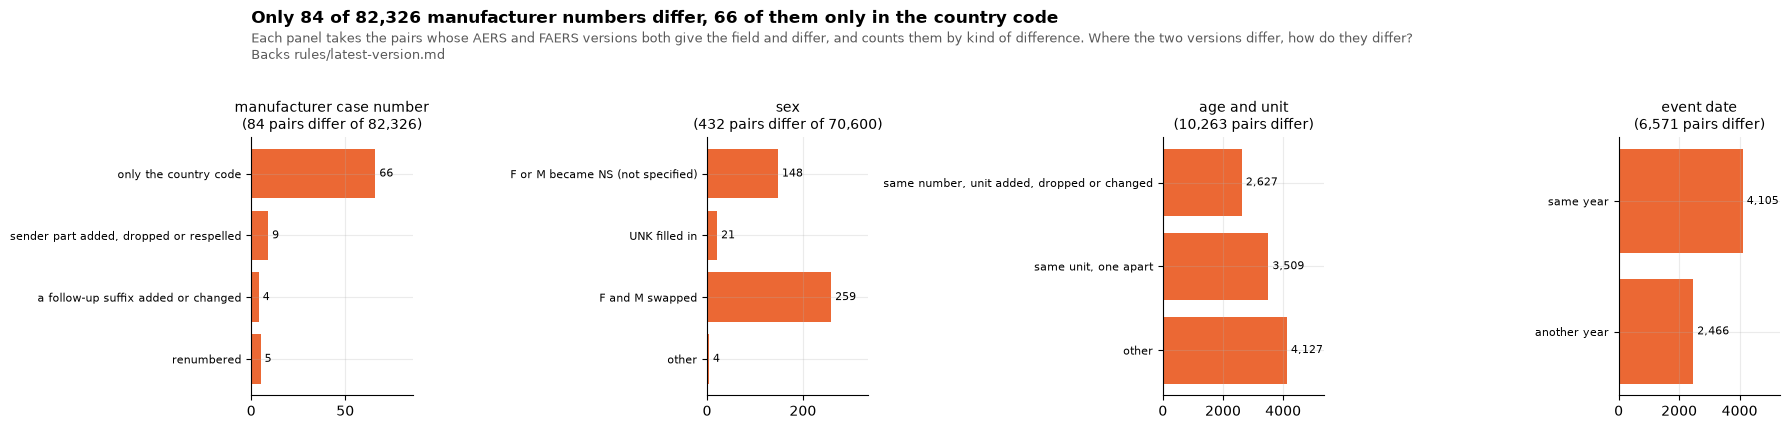

Manufacturer numbers: 84 of 82,326 differ; 66 only in the country code (65 of them now EU-), 9 in the sender part, 4 in a follow-up suffix, 5 renumbered.
Sex: 432 of 70,600 differ: F or M became NS (not specified) 148, UNK filled in 21, F and M swapped 259, other 4.
Ages that differ: 10,263; same number with the unit added, dropped or changed 26%, same unit and one apart 34%. Event dates that differ: 6,571, of which 62% keep the same year.


In [11]:
COUNTRY_ONLY = """strpos(l, '-') > 0 AND strpos(f, '-') > 0 AND length(split_part(l, '-', 1)) <= 2 AND length(split_part(f, '-', 1)) <= 2
                  AND substr(l, strpos(l, '-')) = substr(f, strpos(f, '-'))"""  # only the country code before the first hyphen differs
SENDER = """(ends_with(l, '-' || f) OR ends_with(f, '-' || l)
            OR (strpos(l, '-') > 0 AND strpos(f, '-') > 0 AND regexp_extract(l, '[^-]*$') = regexp_extract(f, '[^-]*$')))"""  # same number after the last hyphen
SUFFIX = r"""regexp_replace(l, '\s*(-\s*[0-9]{1,2}|\([0-9]{1,2}\))$', '') = regexp_replace(f, '\s*(-\s*[0-9]{1,2}|\([0-9]{1,2}\))$', '')"""  # a short follow-up suffix
mfr = q(f"""
WITH d AS (SELECT upper(l_mfr) l, upper(f_mfr) f FROM pairs_T WHERE l_mfr IS NOT NULL AND f_mfr IS NOT NULL),
     k AS (SELECT l, f, CASE WHEN l = f THEN NULL WHEN {COUNTRY_ONLY} THEN 'only the country code' WHEN {SENDER} THEN 'sender part added, dropped or respelled'
                             WHEN {SUFFIX} THEN 'a follow-up suffix added or changed' ELSE 'renumbered' END kind FROM d)
SELECT count(*) n_both, count(kind) n_differ,
       count(*) FILTER (WHERE kind = 'only the country code') "only the country code",
       count(*) FILTER (WHERE kind = 'only the country code' AND left(f, 3) = 'EU-') prefix_to_eu,
       count(*) FILTER (WHERE kind = 'sender part added, dropped or respelled') "sender part added, dropped or respelled",
       count(*) FILTER (WHERE kind = 'a follow-up suffix added or changed') "a follow-up suffix added or changed",
       count(*) FILTER (WHERE kind = 'renumbered') "renumbered"
FROM k""").iloc[0]
sex = q("""
WITH d AS (SELECT l_sex l, f_sex f FROM pairs_T WHERE l_sex IS NOT NULL AND f_sex IS NOT NULL)
SELECT count(*) n_both, count(*) FILTER (WHERE l <> f) n_differ,
       count(*) FILTER (WHERE l IN ('F', 'M') AND f = 'NS') "F or M became NS (not specified)",
       count(*) FILTER (WHERE l = 'UNK' AND f IN ('F', 'M')) "UNK filled in",
       count(*) FILTER (WHERE l IN ('F', 'M') AND f IN ('F', 'M') AND l <> f) "F and M swapped"
FROM d""").iloc[0]
sex["other"] = sex.n_differ - sex.iloc[2:].sum()
age = q("""
WITH d AS (SELECT l_age, f_age, l_age_cod, f_age_cod, try_cast(l_age AS DOUBLE) la, try_cast(f_age AS DOUBLE) fa FROM pairs_T
           WHERE l_age IS NOT NULL AND f_age IS NOT NULL AND NOT (l_age = f_age AND l_age_cod IS NOT DISTINCT FROM f_age_cod))
SELECT count(*) n_differ,
       count(*) FILTER (WHERE l_age = f_age) "same number, unit added, dropped or changed",
       count(*) FILTER (WHERE l_age <> f_age AND l_age_cod IS NOT DISTINCT FROM f_age_cod AND abs(la - fa) = 1) "same unit, one apart",
       count(*) FILTER (WHERE l_age <> f_age AND NOT (l_age_cod IS NOT DISTINCT FROM f_age_cod AND coalesce(abs(la - fa) = 1, false))) "other"
FROM d""").iloc[0]
evt = q("""
WITH d AS (SELECT l_event, f_event FROM pairs_T WHERE l_event IS NOT NULL AND f_event IS NOT NULL AND left(l_event, length(f_event)) <> f_event)
SELECT count(*) n_differ, count(*) FILTER (WHERE left(l_event, 4) = left(f_event, 4)) "same year", count(*) FILTER (WHERE left(l_event, 4) <> left(f_event, 4)) "another year"
FROM d""").iloc[0]
panels = [
    (
        "manufacturer case number",
        mfr,
        [
            "only the country code",
            "sender part added, dropped or respelled",
            "a follow-up suffix added or changed",
            "renumbered",
        ],
        mfr.n_both,
    ),
    (
        "sex",
        sex,
        ["F or M became NS (not specified)", "UNK filled in", "F and M swapped", "other"],
        sex.n_both,
    ),
    (
        "age and unit",
        age,
        ["same number, unit added, dropped or changed", "same unit, one apart", "other"],
        None,
    ),
    ("event date", evt, ["same year", "another year"], None),
]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (name, s_, kinds, n_both) in zip(axes, panels, strict=True):
    vals = [int(s_[k]) for k in kinds]
    label_bars(ax, ax.barh(kinds[::-1], vals[::-1], color=SERIES[1]), horizontal=True)
    ax.set_title(
        f"{name}\n({int(s_.n_differ):,} pairs differ"
        + (f" of {int(n_both):,})" if n_both is not None else ")"),
        fontsize=10,
    )
    ax.tick_params(axis="y", labelsize=8)
    ax.set_xlim(0, max(vals) * 1.3)
plt.tight_layout(rect=(0, 0, 1, 0.76))
left, right = axes[0].get_position().x0, axes[-1].get_position().x1
head = fig.add_axes([left, 0.79, right - left, 0.001])
head.axis("off")  # the figure's title sits on this empty strip
title(
    head,
    f"Only {int(mfr.n_differ)} of {int(mfr.n_both):,} manufacturer numbers differ, {int(mfr['only the country code'])} of them only in the country code",
    "Each panel takes the pairs whose AERS and FAERS versions both give the field and differ, and counts them by kind of difference.",
    "Where the two versions differ, how do they differ?",
    backs="Backs rules/latest-version.md",
    width=200,
)
plt.show()
print(
    f"Manufacturer numbers: {mfr.n_differ:,} of {mfr.n_both:,} differ; {mfr['only the country code']} only in the country code "
    f"({mfr.prefix_to_eu} of them now EU-), {mfr['sender part added, dropped or respelled']} in the sender part, "
    f"{mfr['a follow-up suffix added or changed']} in a follow-up suffix, {mfr['renumbered']} renumbered."
)
print(
    f"Sex: {sex.n_differ:,} of {sex.n_both:,} differ: "
    + ", ".join(f"{k} {int(sex[k])}" for k in sex.index[2:])
    + "."
)
print(
    f"Ages that differ: {age.n_differ:,}; same number with the unit added, dropped or changed "
    f"{100 * age['same number, unit added, dropped or changed'] / age.n_differ:.0f}%, same unit and one apart {100 * age['same unit, one apart'] / age.n_differ:.0f}%. "
    f"Event dates that differ: {evt.n_differ:,}, of which {100 * evt['same year'] / evt.n_differ:.0f}% keep the same year."
)

The differences are the ordinary work of follow-ups and of FAERS's own conventions, not signs of two different cases. Manufacturer numbers: 84 of 82,326 differ. 66 differ only in the country code at the front (65 of them now `EU-`, as European senders moved to it). 9 keep the same number but add, drop or respell the sender part (4 of those only write `&` as `+`). 4 add or change a short follow-up suffix such as `-1` or `(01)`, and 5 were renumbered by the company. Sex: about 430 of 70,600 differ; about 150 went from a known sex to `NS` (not specified), about 20 filled in an `UNK`, and about 260 swapped F and M, a correction either way. Ages that differ mostly keep the number and add, drop or change the unit (about a quarter), or move by one (about a third), as a birthday or a corrected age would. Event dates that differ keep the same year in about six in ten.

### Examples, and how FAERS numbered the versions

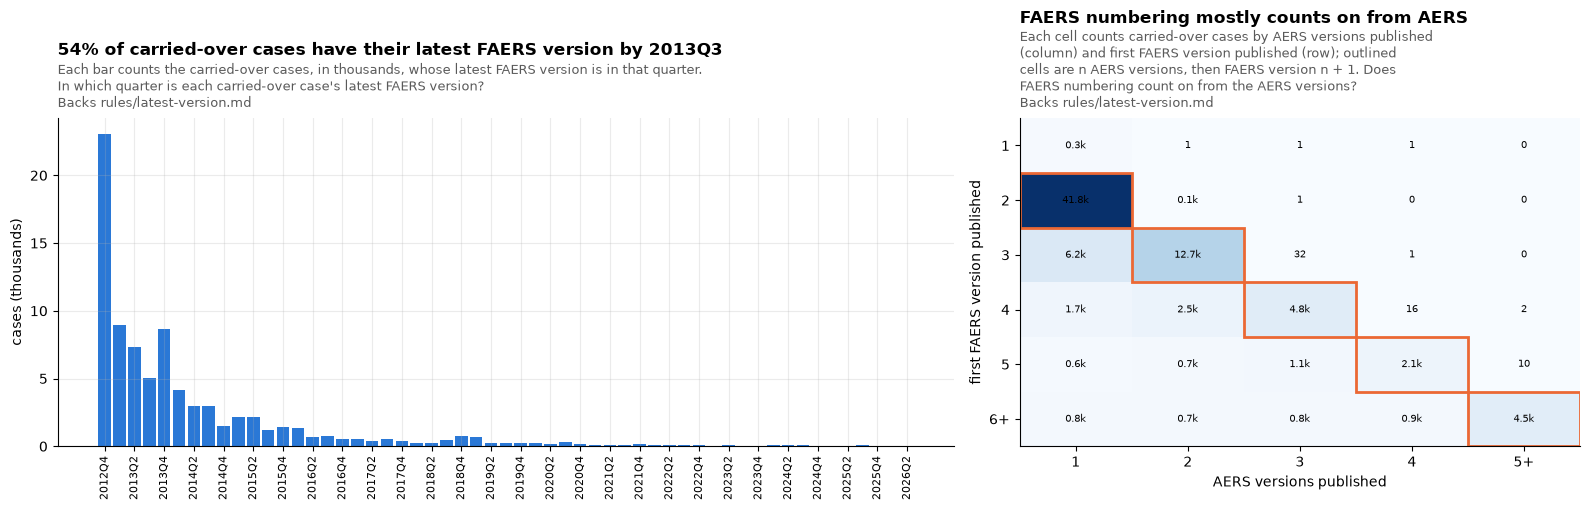

FAERS counts on (first FAERS version = AERS versions + 1): 63,898. Skips numbers (versions never published): 17,902. Exceptions (first FAERS version at or below the AERS count): 542.
Received before the latest AERS version: 0 latest FAERS versions, 1 first FAERS versions (0 among the exceptions). The exceptions:
                         how                               what   n  faers_older
repeats the last AERS number 2012 to 2014 follow-up, later date 101            0
repeats the last AERS number             2020Q3 copy, same date  72            0
repeats the last AERS number                    later follow-up  10            0
               restarts at 1 2012 to 2014 follow-up, later date 295            0
               restarts at 1             2020Q3 copy, same date  56            0
steps back to a lower number 2012 to 2014 follow-up, later date   4            0
steps back to a lower number             2020Q3 copy, same date   1            0
steps back to a lower number          

,caseid,aers_isr,aers_fda_dt,faers_primaryid,faers_version,faers_init_fda_dt,faers_fda_dt,aers_mfr_num,faers_mfr_num,sex_aers_faers,age_aers_faers,event_aers_faers,country_aers_faers
0,6578561,5661319,20080312,65785612,2,20080312,20200610,RO-JNJFOC-20080302132,RO-JNJFOC-20080302132,F / F,47 YR / 47 YR,/,ROMANIA / RO
1,8042767,7681489,20110812,80427675,5,20110718,20140702,PHHO2011JP09992,PHHO2011JP09992,F / F,38 YR / 38 YR,20110526 / 20110526,JAPAN / JP
2,8664869,8494615,20120405,86648692,2,20120405,20120628,PHHY2011US33864,PHHY2011US33864,F / F,65 YR / 65 YR,20110418 / 20110418,UNITED STATES / US
3,8736851,8612374,20120822,87368516,6,20120822,20121207,US-ENDO PHARMACEUTICALS INC.-OPCR20121769,US-ENDO PHARMACEUTICALS INC.-OPCR20121769,F / F,YR / 45,20120101 / 2012,UNITED STATES / US
4,8740559,8617069,20120823,87405593,3,20120823,20131003,US-009507513-1208USA007387,US-009507513-1208USA007387,/ F,YR /,20020101 / 2002,UNITED STATES / US
5,8492060,8256621,20120403,84920602,2,20120403,20120830,US-BAYER-2012-029783,US-BAYER-2012-029783,F / F,26 YR / 26 YR,20091201 / 200912,UNITED STATES / US


In [12]:
ex = q("""SELECT caseid, lp AS aers_isr, l_fda AS aers_fda_dt, fp AS faers_primaryid, f_cv AS faers_version, f_init AS faers_init_fda_dt, f_fda AS faers_fda_dt,
              l_mfr AS aers_mfr_num, f_mfr AS faers_mfr_num, coalesce(l_sex, '') || ' / ' || coalesce(f_sex, '') AS sex_aers_faers,
              coalesce(l_age, '') || ' ' || coalesce(l_age_cod, '') || ' / ' || coalesce(f_age, '') || ' ' || coalesce(f_age_cod, '') AS age_aers_faers,
              coalesce(l_event, '') || ' / ' || coalesce(f_event, '') AS event_aers_faers, coalesce(l_country, '') || ' / ' || coalesce(f_country, '') AS country_aers_faers
       FROM pairs_T ORDER BY hash(caseid) LIMIT 6""")
when = q("SELECT fq, count(*) n FROM pairs_T GROUP BY 1 ORDER BY 1")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
a1.bar(range(len(when)), when.n / 1e3, color=SERIES[0], width=0.85)
quarter_ticks(a1, when.fq, every=2)
a1.set_ylabel("cases (thousands)")
title(
    a1,
    f"{100 * when.n[when.fq <= '2013q3'].sum() / when.n.sum():.0f}% of carried-over cases have their latest FAERS version by 2013Q3",
    "Each bar counts the carried-over cases, in thousands, whose latest FAERS version is in that quarter.",
    "In which quarter is each carried-over case's latest FAERS version?",
    backs="Backs rules/latest-version.md",
    width=100,
)
cv = (
    q(
        "SELECT least(n_legacy, 5) aers_versions, least(first_cv, 6) first_faers_version, count(*) n FROM pairs_T GROUP BY ALL"
    )
    .pivot(index="first_faers_version", columns="aers_versions", values="n")
    .fillna(0)
)
im = a2.imshow(cv.values, cmap="Blues", aspect="auto")
a2.grid(False)
a2.set_xticks(range(len(cv.columns)))
a2.set_xticklabels([f"{int(c)}" + ("+" if c == 5 else "") for c in cv.columns])
a2.set_yticks(range(len(cv.index)))
a2.set_yticklabels([f"{int(c)}" + ("+" if c == 6 else "") for c in cv.index])
a2.set_xlabel("AERS versions published")
a2.set_ylabel("first FAERS version published")
for j, c in enumerate(
    cv.columns
):  # outline the cells where FAERS counts on: n AERS versions, then FAERS version n + 1
    if c + 1 in cv.index:
        a2.add_patch(
            plt.Rectangle(
                (j - 0.5, list(cv.index).index(c + 1) - 0.5), 1, 1, fill=False, ec=SERIES[1], lw=2
            )
        )
title(
    a2,
    "FAERS numbering mostly counts on from AERS",
    "Each cell counts carried-over cases by AERS versions published (column) and first FAERS version published (row); outlined cells are "
    "n AERS versions, then FAERS version n + 1.",
    "Does FAERS numbering count on from the AERS versions?",
    backs="Backs rules/latest-version.md",
    width=62,
)
for (i, j), v in np.ndenumerate(cv.values):
    a2.text(
        j, i, f"{v / 1e3:.1f}k" if v >= 100 else f"{v:.0f}", ha="center", va="center", fontsize=7
    )
plt.tight_layout()
plt.show()
xc = q("""
SELECT CASE WHEN first_cv = 1 THEN 'restarts at 1' WHEN first_cv = n_legacy THEN 'repeats the last AERS number' ELSE 'steps back to a lower number' END how,
       CASE WHEN first_q = '2020q3' AND first_f_fda = l_fda THEN '2020Q3 copy, same date'
            WHEN first_q BETWEEN '2012q4' AND '2014q4' AND first_f_fda > l_fda THEN '2012 to 2014 follow-up, later date'
            ELSE 'later follow-up' END what, count(*) n,
       count(*) FILTER (WHERE first_f_fda < l_fda) faers_older
FROM pairs_T WHERE first_cv <= n_legacy GROUP BY ALL ORDER BY ALL""")
older = one(
    "SELECT count(*) FILTER (WHERE f_fda < l_fda), count(*) FILTER (WHERE first_f_fda < l_fda) FROM pairs_T"
)
skipped = one("SELECT count(*) FROM pairs_T WHERE first_cv > n_legacy + 1")[0]
print(
    f"FAERS counts on (first FAERS version = AERS versions + 1): {one('SELECT count(*) FROM pairs_T WHERE first_cv = n_legacy + 1')[0]:,}. "
    f"Skips numbers (versions never published): {skipped:,}. Exceptions (first FAERS version at or below the AERS count): {xc.n.sum():,}."
)
print(
    f"Received before the latest AERS version: {older[0]} latest FAERS versions, {older[1]} first FAERS versions "
    f"({xc.faers_older.sum()} among the exceptions). The exceptions:"
)
print(xc.to_string(index=False))
print(xc.groupby("how").n.sum().to_string(), xc.groupby("what").n.sum().to_string(), sep="\n")
ex

**Reading the heatmap.** Each column is how many AERS versions a carried-over case had; each row is the number of its first FAERS version. FAERS numbering counts on from AERS: a case with two AERS versions usually continues at FAERS version 3, the outlined cells. Cells further down skipped numbers: versions FDA filed but never published (section 1). The cells on or above the diagonal are the exceptions, about 540: about 350 restart at 1, about 180 repeat the last AERS number, and 8 step back to a lower one. About 130 of them are copies FDA republished in 2020Q3 with the same date as the AERS version; about 400 are follow-ups from 2012 to 2014 with later dates; 13 are later follow-ups. An AERS report FDA published again in a later quarter counts once: it is the same version. None of the exceptions is older than its AERS version, and every carried-over case's latest FAERS version was received on or after its latest AERS one, so choosing the FAERS version is always choosing the newest.

### Picking one latest version per case across eras

Ordered as the release orders versions (highest `caseversion`, then latest `fda_dt`, then quarter, then `primaryid`), the FAERS version always wins, because legacy versions have no `caseversion`. AEOLUS picks across eras too, but sorts `primaryid` as text. Text is compared one character at a time, so `…9` sorts after `…10` (9 is greater than 1, the first character that differs), just as "9" comes after "10" in a dictionary. `primaryid` is the case number followed by the version, so a text sort can pick version 9 over version 10.

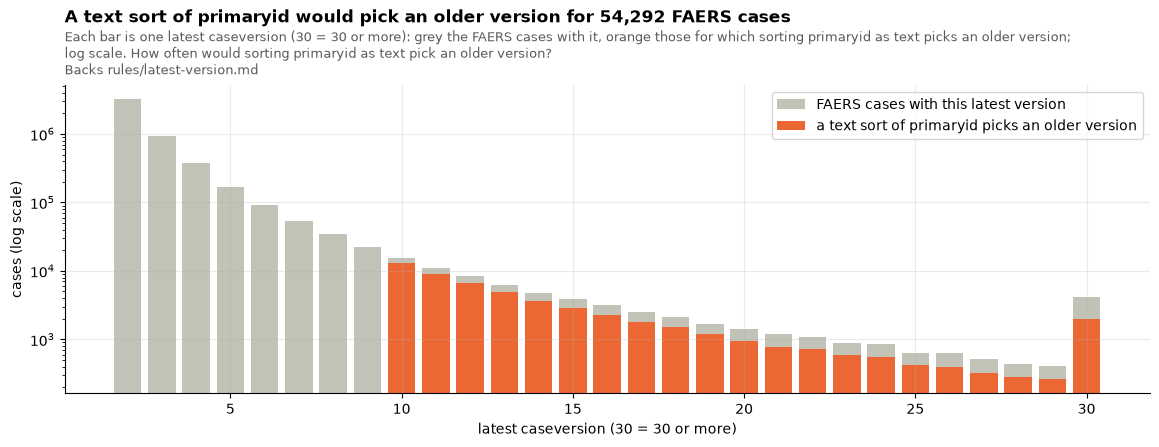

Carried-over pairs where the FAERS version was received on or after the AERS one: 82,342 of 82,342. A text sort would pick an older version for 54,292 FAERS cases, all with a latest version of 10 or more (71,610 such cases). The pipeline keeps the numeric order.


In [13]:
later = q(
    "SELECT count(*) n, count(*) FILTER (WHERE f_fda >= l_fda) faers_later FROM pairs_T"
).iloc[0]
ts = q("""
WITH r AS (SELECT caseid, caseversion_T,
                  row_number() OVER (PARTITION BY caseid ORDER BY caseversion_T DESC NULLS LAST, fda_dt DESC NULLS LAST, qnum_T DESC, primaryid DESC) rn_num,
                  row_number() OVER (PARTITION BY caseid ORDER BY primaryid DESC, qnum_T DESC) rn_text
           FROM demo_T WHERE era_T = 'faers')
SELECT least(caseversion_T, 30) latest_version, count(*) cases, count(*) FILTER (WHERE rn_text <> 1) text_sort_older
FROM r WHERE rn_num = 1 AND caseversion_T >= 2 GROUP BY 1 ORDER BY 1""")
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(ts.latest_version, ts.cases, color=SERIES[7], label="FAERS cases with this latest version")
ax.bar(
    ts.latest_version,
    ts.text_sort_older,
    color=SERIES[1],
    label="a text sort of primaryid picks an older version",
)
ax.set_yscale("log")
ax.set_xlabel("latest caseversion (30 = 30 or more)")
ax.set_ylabel("cases (log scale)")
title(
    ax,
    f"A text sort of primaryid would pick an older version for {ts.text_sort_older.sum():,} FAERS cases",
    "Each bar is one latest caseversion (30 = 30 or more): grey the FAERS cases with it, orange those for which sorting primaryid as text "
    "picks an older version; log scale.",
    "How often would sorting primaryid as text pick an older version?",
    backs="Backs rules/latest-version.md",
    width=157,
)
ax.legend()
plt.show()
print(
    f"Carried-over pairs where the FAERS version was received on or after the AERS one: {later.faers_later:,} of {later.n:,}. "
    f"A text sort would pick an older version for {ts.text_sort_older.sum():,} FAERS cases, all with a latest version of 10 or more "
    f"({ts[ts.latest_version >= 10].cases.sum():,} such cases). The pipeline keeps the numeric order."
)

## 4. What did the three broken 2011 DRUG lines lose?

In 2011Q2, 2011Q3 and 2011Q4 the DRUG file has one line each where a record runs on into the next with no line break. A reader that guesses the column count from the rows cuts such a line short in silence: each second record is lost, and nothing reports it. This section reads FDA's zips directly, because it is about the loader.

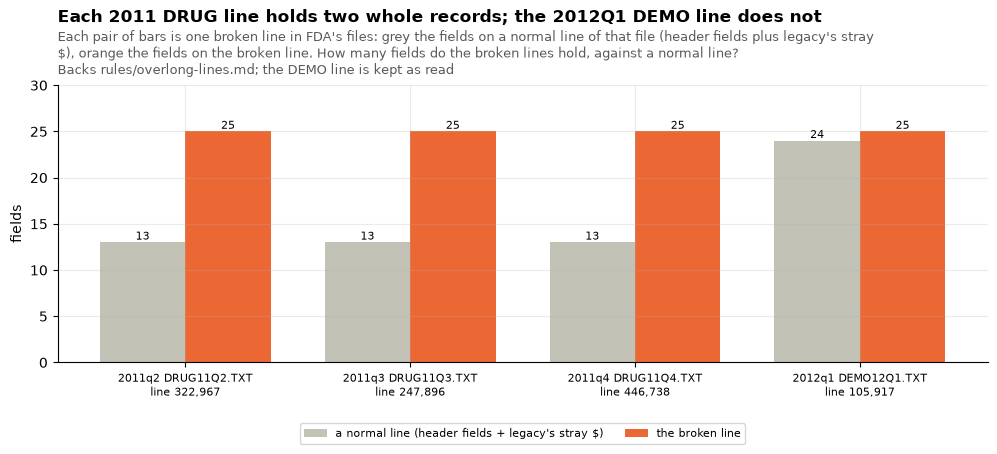

,quarter,file,line,header fields,fields on the line,whole records on it,text
0,2011q2,ascii/DRUG11Q2.TXT,322967,12,25,2.000000,"7475791$1016572493$SS$BLEOMYCIN SULFATE$1$INTRAVENOUS$10 MG/M2 MILLIGRAM(S)/SQ. METER,..."
1,2011q3,ascii/DRUG11Q3.TXT,247896,12,25,2.000000,7652730$1017185838$PS$FLUOROURACIL$1$$10140 MG$$$$$$7652730$1017255397$SS$BEVACIZUMAB ...
2,2011q4,ascii/DRUG11Q4.TXT,446738,12,25,2.000000,"7941354$1018142410$PS$MEMANTINE HYDROCHLORIDE$1$ORAL$5 MG (5 MG, 1 IN 1 D),ORAL , 105 ..."
3,2012q1,ascii/DEMO12Q1.TXT,105917,23,25,1.043478,8129732$8401177$I$$8129732-9$20120126$20120206$20120210$EXP$JP-CUBIST-$E2B0000000182$C...


In [14]:
assert ZIPS, (
    "set ZIP_FOLDER in the first code cell, or OPEN_ALTIO_ZIPS, to the folder of FDA's zips"
)
quarters_in = {x.name: x for x in discover(Path(ZIPS).expanduser())}


def line_of(quarter, table, needle):
    qz = quarters_in[quarter]
    member = qz.table_file(table)
    with zipfile.ZipFile(qz.path) as z, z.open(member) as f:
        header = f.readline().decode("utf-8", "replace").rstrip("\r\n")
        for n, raw in enumerate(f, start=2):
            if needle.encode() in raw:
                return member, n, header, raw.decode("utf-8", "replace").rstrip("\r\n")


BROKEN = [
    ("2011q2", "drug", "$$$$$$7475791$"),
    ("2011q3", "drug", "$$$$$$7652730$"),
    ("2011q4", "drug", "021487$7941354$"),
    ("2012q1", "demo", "JP-CUBIST-$E2B0000000182"),
]  # the fourth: a '$' inside a value (below)
rows = []
for quarter, table, needle in BROKEN:
    member, n, header, line = line_of(quarter, table, needle)
    width = len(header.split("$"))
    fields = line.split("$")
    rows.append(
        {
            "quarter": quarter,
            "file": member,
            "line": n,
            "header fields": width,
            "fields on the line": len(fields),
            "whole records on it": (len(fields) - 1) / width,
            "text": line[:160] + ("…" if len(line) > 160 else ""),
        }
    )
broken = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(12, 3.6))
x = np.arange(len(broken))
w = 0.38
label_bars(
    ax,
    ax.bar(
        x - w / 2,
        broken["header fields"] + 1,
        w,
        color=SERIES[7],
        label="a normal line (header fields + legacy's stray $)",
    ),
)
label_bars(
    ax, ax.bar(x + w / 2, broken["fields on the line"], w, color=SERIES[1], label="the broken line")
)
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{r.quarter} {r.file.split('/')[-1]}\nline {r.line:,}" for r in broken.itertuples()],
    fontsize=8,
)
ax.set_ylabel("fields")
ax.set_ylim(0, 30)
title(
    ax,
    "Each 2011 DRUG line holds two whole records; the 2012Q1 DEMO line does not",
    "Each pair of bars is one broken line in FDA's files: grey the fields on a normal line of that file (header fields plus legacy's stray $), "
    "orange the fields on the broken line.",
    "How many fields do the broken lines hold, against a normal line?",
    backs="Backs rules/overlong-lines.md; the DEMO line is kept as read",
    width=135,
)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.show()
broken

The three DRUG lines hold exactly two whole records each (12 fields, then 12 more, then the stray `$`), so they can be split with no judgement. The 2012Q1 DEMO line is different: a `$` inside the manufacturer number (`JP-CUBIST-$E2B0000000182`) pushes every later value one column right; that is not two records, and AEOLUS fixes it by hand.

A scan of all 630 case files (every line's field count against its header) finds no other line longer than its header and none shorter.

**The rule** (`rules/overlong-lines.md`, `src/open_altio/faers/load.py`): the header line sets the columns, and a longer line is never cut in silence. A line of whole records is split back into them; any other keeps its first fields, and the text past the last column is written into the manifest. Every such line is listed under `inputs[].overlong_lines`. No value changes: the split only puts back the line break FDA left out.

### Does the fix put the lost drugs back?

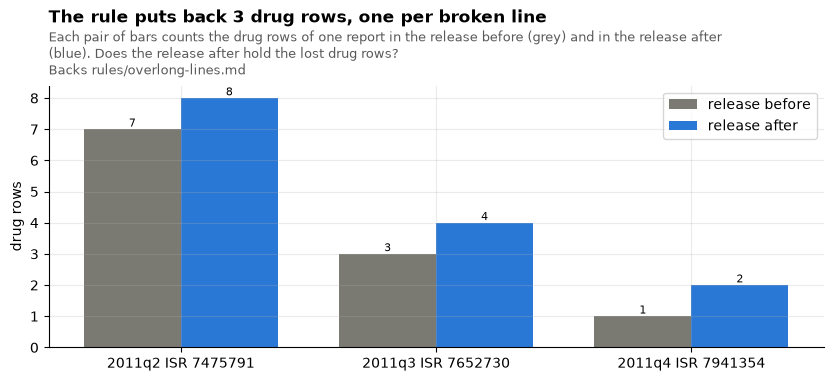

Rows in the release after that the release before lacks:
  2011q2 ISR 7475791: drug 1016572490 DOXORUBICIN (DOXORUBICIN) (INJECTION)
  2011q3 ISR 7652730: drug 1017255397 BEVACIZUMAB (RHUMAB VEGF)
  2011q4 ISR 7941354: drug 1018188213 MEMANTINE HYDROCHLORIDE
Raw table rows, after less before: demo +0, drug +3, reac +0, outc +0, rpsr +0, ther +0, indi +0, deleted +0
Recorded in its manifest:
  2011q2 drug: {'line': 322967, 'fields': 25, 'records': 2}
  2011q3 drug: {'line': 247896, 'fields': 25, 'records': 2}
  2011q4 drug: {'line': 446738, 'fields': 25, 'records': 2}
  2012q1 demo: {'line': 105917, 'fields': 25, 'records': 1, 'dropped': 'JAPAN$'}
Of the three reports, 2 are their case's latest version. The case of 7652730 has a full duplicate key; adding BEVACIZUMAB to its drug set matches no other case, so no duplicate flag moves.


,quarter_T,primaryid,drug_rows,drugs,caseid,is_latest_version,drug_rows_after,drugs_after
0,2011q2,7475791,7,MUSTARGEN | VINCRISTINE | PROCARBAZINE HYDROCHLORIDE | PREDNISONE | BLEOMYCIN SULFATE ...,7952459,True,8,MUSTARGEN | VINCRISTINE | PROCARBAZINE HYDROCHLORIDE | PREDNISONE | DOXORUBICIN (DOXOR...
1,2011q3,7652730,3,FLUOROURACIL | LEUCOVORIN CALCIUM | ELOXATIN,8079763,True,4,FLUOROURACIL | BEVACIZUMAB (RHUMAB VEGF) | LEUCOVORIN CALCIUM | ELOXATIN
2,2011q4,7941354,1,MEMANTINE HYDROCHLORIDE,8268921,False,2,MEMANTINE HYDROCHLORIDE | MEMANTINE HYDROCHLORIDE


In [15]:
ids = [("2011q2", "7475791"), ("2011q3", "7652730"), ("2011q4", "7941354")]
cond = " OR ".join(f"(quarter_T = '{qq}' AND primaryid = '{p}')" for qq, p in ids)
before = q(
    f"SELECT quarter_T, primaryid, count(*) drug_rows, string_agg(drugname, ' | ' ORDER BY drug_seq) drugs FROM drug WHERE {cond} GROUP BY ALL ORDER BY 1"
)
latest = q(f"""SELECT d.quarter_T, d.primaryid, d.caseid, l.primaryid = d.primaryid AS is_latest_version
              FROM demo d JOIN demo_latest_T l ON l.era_T = 'legacy' AND l.case_key_T = coalesce(d.caseid, 'ISR:' || d.primaryid) WHERE {cond.replace("quarter_T", "d.quarter_T").replace("primaryid", "d.primaryid")}""")
after = acon.execute(
    f"SELECT quarter_T, primaryid, count(*) drug_rows_after, string_agg(drugname, ' | ' ORDER BY drug_seq) drugs_after FROM drug WHERE {cond} GROUP BY ALL"
).fetchdf()
tab = before.merge(latest, on=["quarter_T", "primaryid"]).merge(
    after, on=["quarter_T", "primaryid"]
)
COLS = "quarter_T, primaryid, drug_seq, drugname"
restored = (
    acon.execute(f"SELECT {COLS} FROM drug WHERE {cond}")
    .fetchdf()
    .merge(
        con.execute(f"SELECT {COLS} FROM drug WHERE {cond}").fetchdf(), how="left", indicator=True
    )
    .query("_merge == 'left_only'")
    .drop(columns="_merge")
)
raw_rows = {
    t: (e["rows"], json.loads((AFTER / "manifest.json").read_text())["tables"][t]["rows"])
    for t, e in json.loads((SOURCE / "manifest.json").read_text())["tables"].items()
    if e["kind"] == "raw"
}
recorded = [
    (i["quarter"], i["table"], o)
    for i in json.loads((AFTER / "manifest.json").read_text())["inputs"]
    for o in i.get("overlong_lines", [])
]
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(tab))
w = 0.38
label_bars(ax, ax.bar(x - w / 2, tab.drug_rows, w, color=SERIES[6], label="release before"))
label_bars(ax, ax.bar(x + w / 2, tab.drug_rows_after, w, color=SERIES[0], label="release after"))
ax.set_xticks(x)
ax.set_xticklabels([f"{r.quarter_T} ISR {r.primaryid}" for r in tab.itertuples()])
ax.set_ylabel("drug rows")
title(
    ax,
    f"The rule puts back {int((tab.drug_rows_after - tab.drug_rows).sum())} drug rows, one per broken line",
    "Each pair of bars counts the drug rows of one report in the release before (grey) and in the release after (blue).",
    "Does the release after hold the lost drug rows?",
    backs="Backs rules/overlong-lines.md",
    width=112,
)
ax.legend()
plt.show()
print(
    "Rows in the release after that the release before lacks:",
    *[
        f"{r.quarter_T} ISR {r.primaryid}: drug {r.drug_seq} {r.drugname}"
        for r in restored.itertuples()
    ],
    sep="\n  ",
)
print(
    "Raw table rows, after less before:",
    ", ".join(f"{t} {a - b:+,}" for t, (b, a) in raw_rows.items()),
)
print("Recorded in its manifest:", *[f"{qq} {t}: {o}" for qq, t, o in recorded], sep="\n  ")
print(
    f"Of the three reports, {int(tab.is_latest_version.sum())} are their case's latest version. The case of 7652730 has a full duplicate key; "
    "adding BEVACIZUMAB to its drug set matches no other case, so no duplicate flag moves."
)
tab

The release after holds the three lost drug rows: doxorubicin (2011Q2), bevacizumab (2011Q3) and a second memantine row (2011Q4). Every other raw table has the same number of rows in both releases, and a row-by-row comparison of every value finds these three rows the only difference.

**The 2012Q1 DEMO line** (case 8401177, its only version): its values sit one column right, so its age reads as the sender's name and its country is empty. It is kept as read and recorded in the manifest, with no hand repair.

## 5. Should legacy cases on FDA's deleted lists leave the case set, as FAERS cases do?

**What the deleted lists are.** FDA withdraws cases from its database, "for various reasons including combining cases" (FAQ 44). It never reissues an old quarterly file, so a withdrawn case stays in every file that already holds it. Instead, since 2019Q1 FDA publishes lists of the case numbers it deleted: one each quarter, plus a one-off list of every deletion before then (the whole-history list). The release before takes FAERS cases on the lists out of the case set and keeps legacy cases, 6,304 of them (6,074 once gap B is fixed). DiAna and AEOLUS take those out too.

**The question.** The lists could be read as naming FAERS case numbers only; this section checks whether the legacy numbers on them are legacy cases.

### Are the listed numbers in the AERS range AERS cases?

Highest AERS case number: 8,750,738; set aside as stray: ['1000000032'].


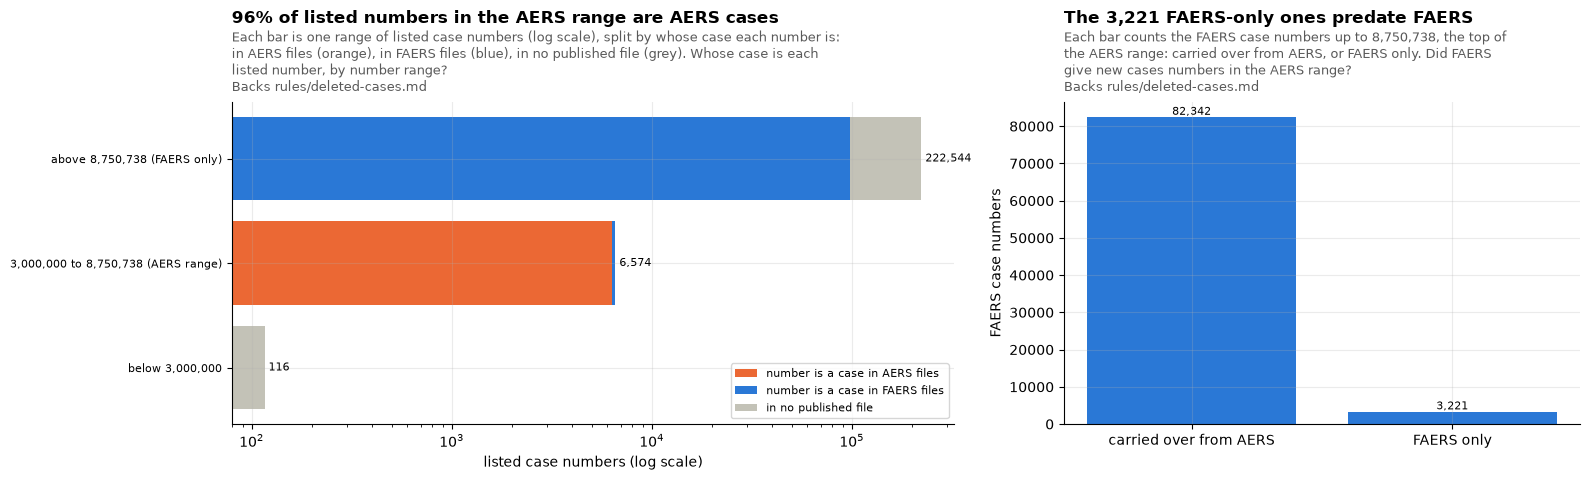

FAERS case numbers in the AERS range: 85,563. 82,342 are cases carried over from AERS (section 3). The other 3,221 have no version in the AERS files: 3,221 were first received before FAERS began (2012-09-10), and 2,953 were first published in 2020Q3.


,band,listed,in_legacy_files,in_faers_files,on_the_whole_history_list
0,"below 3,000,000",116,0,0,116
1,"3,000,000 to 8,750,738 (AERS range)",6574,6304,232,6303
2,"above 8,750,738 (FAERS only)",222544,0,97855,77424


In [16]:
LEG_MAX, stray = (
    one("""SELECT max(try_cast(caseid AS BIGINT)) FILTER (WHERE length(caseid) <= 8), list(DISTINCT caseid) FILTER (WHERE length(caseid) > 8)
                        FROM demo WHERE era_T = 'legacy'""")
)  # one stray ten-digit CASE number is not the range
print(f"Highest AERS case number: {LEG_MAX:,}; set aside as stray: {stray}.")
band = q(f"""
SELECT CASE WHEN try_cast(caseid AS BIGINT) < 3000000 THEN 'below 3,000,000'
            WHEN try_cast(caseid AS BIGINT) <= {LEG_MAX} THEN '3,000,000 to {LEG_MAX:,} (AERS range)'
            ELSE 'above {LEG_MAX:,} (FAERS only)' END band,
       count(*) listed,
       count(*) FILTER (WHERE caseid IN (SELECT caseid FROM demo WHERE era_T = 'legacy')) in_legacy_files,
       count(*) FILTER (WHERE caseid IN (SELECT caseid FROM demo WHERE era_T = 'faers')) in_faers_files,
       count(*) FILTER (WHERE in_all_history_list_T) on_the_whole_history_list
FROM deleted_cases_T GROUP BY 1 ORDER BY min(try_cast(caseid AS BIGINT))""")
rng = q(f"""
WITH f AS (SELECT caseid, min(first_fda_dt_T) received, min(quarter_T) first_published FROM demo_T
           WHERE era_T = 'faers' AND try_cast(caseid AS BIGINT) <= {LEG_MAX} GROUP BY 1)
SELECT coalesce(caseid IN (SELECT caseid FROM demo WHERE era_T = 'legacy' AND caseid IS NOT NULL), false) has_legacy_versions, count(*) n,
       count(*) FILTER (WHERE received < DATE '{FAERS_START}') received_before_faers,
       count(*) FILTER (WHERE first_published = '2020q3') first_published_2020q3 FROM f GROUP BY 1""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.9), gridspec_kw={"width_ratios": [1.4, 1]})
b = band.set_index("band")
left = np.zeros(len(b))
y = np.arange(len(b))
for col, color, label in [
    ("in_legacy_files", SERIES[1], "number is a case in AERS files"),
    ("in_faers_files", SERIES[0], "number is a case in FAERS files"),
]:
    a1.barh(y, b[col], left=left, color=color, label=label)
    left += b[col].values
a1.barh(y, b.listed - left, left=left, color=SERIES[7], label="in no published file")
for i, v in enumerate(b.listed):
    a1.text(v, i, f" {v:,}", va="center", fontsize=8)
a1.set_xscale("log")
a1.set_yticks(y)
a1.set_yticklabels(b.index, fontsize=8)
a1.set_xlabel("listed case numbers (log scale)")
aers_band = b[b.index.str.contains("AERS range")].iloc[0]
title(
    a1,
    f"{100 * aers_band.in_legacy_files / aers_band.listed:.0f}% of listed numbers in the AERS range are AERS cases",
    "Each bar is one range of listed case numbers (log scale), split by whose case each number is: in AERS files (orange), in FAERS "
    "files (blue), in no published file (grey).",
    "Whose case is each listed number, by number range?",
    backs="Backs rules/deleted-cases.md",
    width=95,
)
a1.legend(fontsize=8)
r2 = rng.set_index("has_legacy_versions")
label_bars(
    a2,
    a2.bar(
        ["carried over from AERS", "FAERS only"],
        [r2.n.get(True, 0), r2.n.get(False, 0)],
        color=SERIES[0],
    ),
)
a2.set_ylabel("FAERS case numbers")
title(
    a2,
    f"The {int(r2.n.get(False, 0)):,} FAERS-only ones predate FAERS",
    f"Each bar counts the FAERS case numbers up to {LEG_MAX:,}, the top of the AERS range: carried over from AERS, or FAERS only.",
    "Did FAERS give new cases numbers in the AERS range?",
    backs="Backs rules/deleted-cases.md",
    width=68,
)
plt.tight_layout()
plt.show()
fo = r2.loc[False]
print(
    f"FAERS case numbers in the AERS range: {r2.n.sum():,}. {r2.n[True]:,} are cases carried over from AERS (section 3). "
    f"The other {fo.n:,} have no version in the AERS files: {fo.received_before_faers:,} were first received before FAERS began "
    f"({FAERS_START}), and {fo.first_published_2020q3:,} were first published in 2020Q3."
)
band

Three things point the same way.

- **One numbering.** FDA's README calls both CASE and CASEID "the case report number", and carried-over cases keep their number (section 3). FAERS never gave a new case a number in the AERS range: the 3,221 FAERS-only numbers there all belong to cases first received before FAERS began, 2,953 of them first published in 2020Q3 (old cases FDA published late), and none is a number used by a case in the AERS files.
- **The lists themselves.** 6,574 listed numbers fall in the AERS range; 96% of them are a case in the AERS files and only 232 are in FAERS files. If they were FAERS numbers, they would be in FAERS files.
- **The whole-history list.** 6,303 of the 6,574 are on FDA's list of deletions from before 2019, which by its name covers deletions from AERS times.

So the legacy numbers on the lists are the same legacy cases, deleted by FDA.

### What are they, and when were they deleted?

The report type (`rept_cod`) says who sent a report: **DIR**, direct, sent straight to FDA by a health professional or a patient; **EXP**, expedited, a company's report of a serious, unexpected event, due within 15 days; **PER**, periodic, a company's report filed with its regular safety summaries.

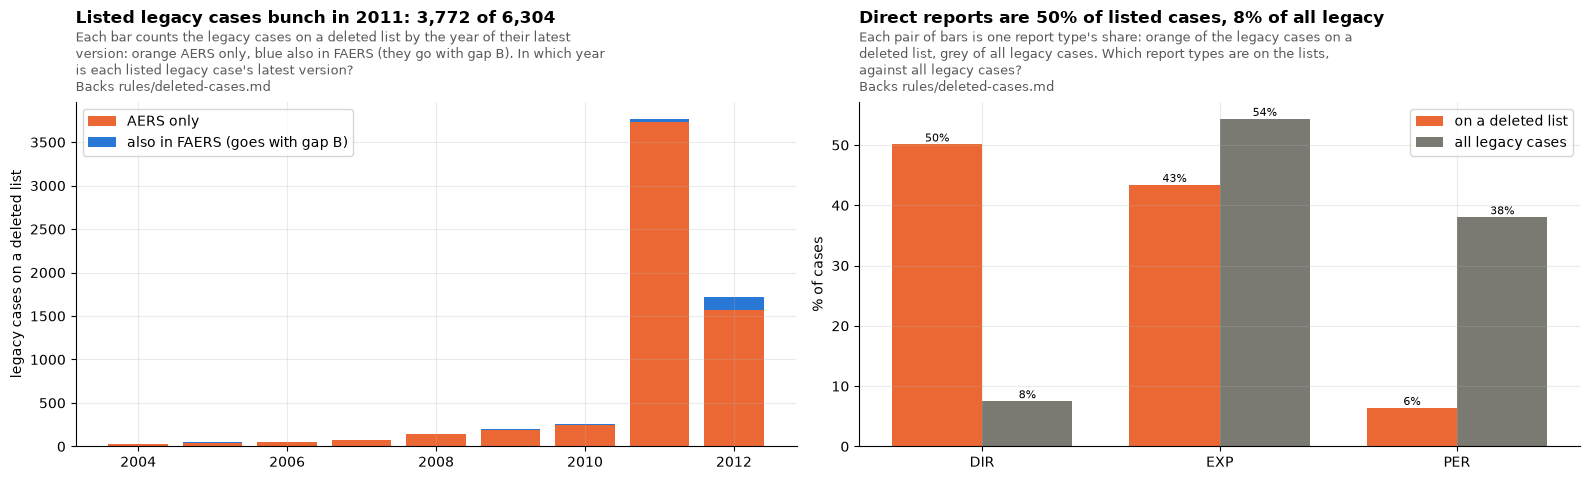

Legacy cases on a list: 6,304; 230 also have a FAERS version, which is deleted, so fixing gap B already drops them; 6,074 are AERS only. Flagged as probable duplicates: 1.7% of them against 0.7% of other legacy cases.


In [17]:
who = q("""
SELECT coalesce(c.caseid IN (SELECT caseid FROM deleted_cases_T), false) listed,
       coalesce(c.caseid IN (SELECT caseid FROM demo_latest_T WHERE era_T = 'faers'), false) carried,
       left(c.quarter_T, 4)::INT yr, c.rept_cod, k.probable_duplicate_T, count(*) n
FROM case_latest_T c JOIN case_dup_T k USING (era_T, case_key_T) WHERE c.era_T = 'legacy' GROUP BY ALL""")
L = who[who.listed]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.9))
yr = L.groupby(["yr", "carried"]).n.sum().unstack().fillna(0)
a1.bar(yr.index, yr.get(False, 0), color=SERIES[1], label="AERS only")
a1.bar(
    yr.index,
    yr.get(True, 0),
    bottom=yr.get(False, 0),
    color=SERIES[0],
    label="also in FAERS (goes with gap B)",
)
a1.set_ylabel("legacy cases on a deleted list")
a1.legend()
title(
    a1,
    f"Listed legacy cases bunch in 2011: {int(yr.loc[2011].sum()):,} of {int(L.n.sum()):,}",
    "Each bar counts the legacy cases on a deleted list by the year of their latest version: orange AERS only, blue also in FAERS (they go with gap B).",
    "In which year is each listed legacy case's latest version?",
    backs="Backs rules/deleted-cases.md",
    width=81,
)
mix = pd.DataFrame(
    {
        "on a deleted list": L.groupby("rept_cod").n.sum(),
        "all legacy cases": who.groupby("rept_cod").n.sum(),
    }
)
mix = 100 * mix / mix.sum()
x = np.arange(len(mix))
w = 0.38
label_bars(
    a2,
    a2.bar(x - w / 2, mix["on a deleted list"], w, color=SERIES[1], label="on a deleted list"),
    "{:.0f}%",
)
label_bars(
    a2,
    a2.bar(x + w / 2, mix["all legacy cases"], w, color=SERIES[6], label="all legacy cases"),
    "{:.0f}%",
)
a2.set_xticks(x)
a2.set_xticklabels(mix.index)
a2.set_ylabel("% of cases")
title(
    a2,
    f"Direct reports are {mix.loc['DIR', 'on a deleted list']:.0f}% of listed cases, {mix.loc['DIR', 'all legacy cases']:.0f}% of all legacy",
    "Each pair of bars is one report type's share: orange of the legacy cases on a deleted list, grey of all legacy cases.",
    "Which report types are on the lists, against all legacy cases?",
    backs="Backs rules/deleted-cases.md",
    width=81,
)
a2.legend()
plt.tight_layout()
plt.show()


def dup(d):
    return 100 * d[d.probable_duplicate_T.eq(True)].n.sum() / d.n.sum()


print(
    f"Legacy cases on a list: {L.n.sum():,}; {L[L.carried].n.sum():,} also have a FAERS version, which is deleted, so fixing gap B already "
    f"drops them; {L[~L.carried].n.sum():,} are AERS only. Flagged as probable duplicates: {dup(L):.1f}% of them against {dup(who[~who.listed]):.1f}% of other legacy cases."
)

Direct reports are over-represented, and the listed cases bunch in 2011. The next chart shows how far: the share of each quarter's cases that FDA later deleted, by the quarter of each case's latest version, with one latest version per case across eras (gap B fixed).

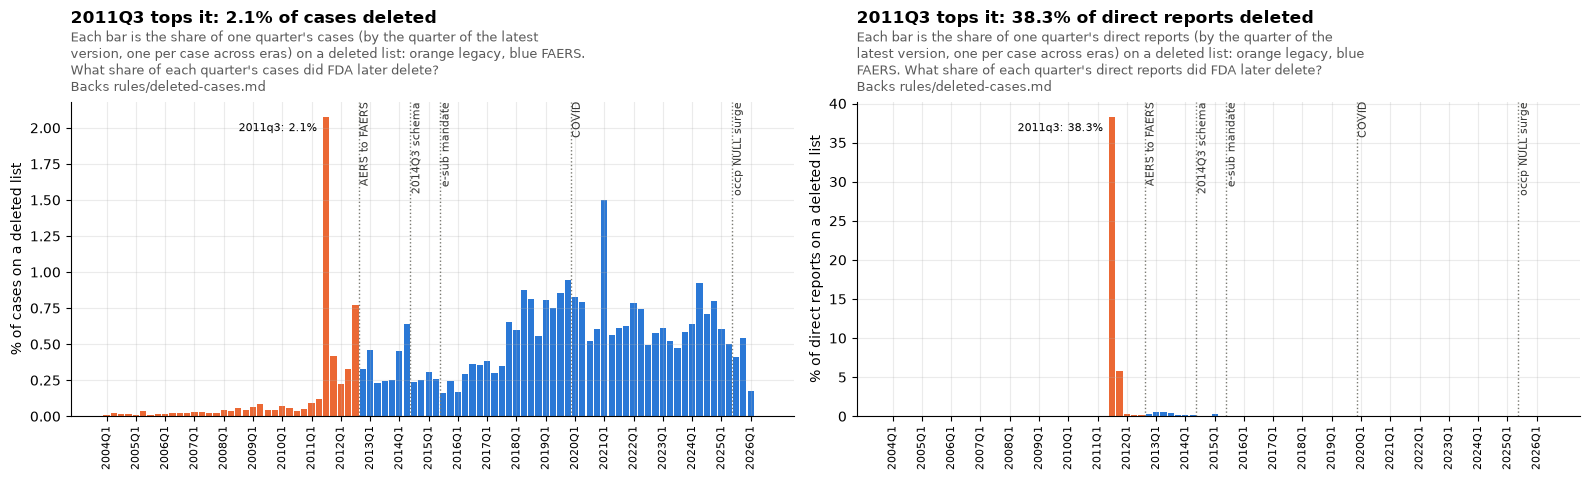

2011Q3: 2,865 of 138,110 cases (2.07%), the highest of 90 quarters (next: 2021q1 at 1.50%). Its direct reports: 2,702 of 7,062 (38%).


In [18]:
con.execute("""
CREATE OR REPLACE TEMP TABLE latest_b_T AS
SELECT d.era_T, d.primaryid, d.caseid, d.quarter_T, d.qnum_T, d.rept_cod, d.e_sub, d.fda_dt_T,
       coalesce(d.caseid IN (SELECT caseid FROM deleted_cases_T), false) AS listed_T
FROM demo_latest_T d
WHERE NOT (d.era_T = 'legacy' AND coalesce(d.caseid IN (SELECT caseid FROM demo_latest_T WHERE era_T = 'faers'), false))""")
sh = q("""SELECT quarter_T, any_value(era_T) era_T, count(*) n, count(*) FILTER (WHERE listed_T) n_del,
                 count(*) FILTER (WHERE rept_cod = 'DIR') n_dir, count(*) FILTER (WHERE rept_cod = 'DIR' AND listed_T) n_dir_del
          FROM latest_b_T GROUP BY 1 ORDER BY min(qnum_T)""")
sh["pct"] = 100 * sh.n_del / sh.n
sh["pct_dir"] = 100 * sh.n_dir_del / sh.n_dir
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.9))
for ax, col, what in [(a1, "pct", "cases"), (a2, "pct_dir", "direct reports")]:
    ax.bar(range(len(sh)), sh[col], color=[ERA[e] for e in sh.era_T], width=0.85)
    quarter_ticks(ax, sh.quarter_T)
    mark_quarters(ax, sh.quarter_T)
    i = int(sh[col].idxmax())
    ax.annotate(
        f"{sh.quarter_T[i]}: {sh[col][i]:.1f}% ",
        (i, sh[col][i]),
        xytext=(-4, -4),
        textcoords="offset points",
        ha="right",
        va="top",
        fontsize=8,
    )
    ax.set_ylabel(f"% of {what} on a deleted list")
    title(
        ax,
        f"{sh.quarter_T[i].upper()} tops it: {sh[col][i]:.1f}% of {what} deleted",
        f"Each bar is the share of one quarter's {what} (by the quarter of the latest version, one per case across eras) on a deleted list: "
        "orange legacy, blue FAERS.",
        f"What share of each quarter's {what} did FDA later delete?",
        backs="Backs rules/deleted-cases.md",
        width=81,
    )
plt.tight_layout()
plt.show()
q3 = sh.set_index("quarter_T").loc["2011q3"]
print(
    f"2011Q3: {q3.n_del:,} of {q3.n:,} cases ({q3.pct:.2f}%), the highest of {len(sh)} quarters "
    f"(next: {sh.sort_values('pct').quarter_T.iloc[-2]} at {sh.sort_values('pct').pct.iloc[-2]:.2f}%). "
    f"Its direct reports: {q3.n_dir_del:,} of {q3.n_dir:,} ({q3.pct_dir:.0f}%)."
)

### What happened in 2011?

From 1 July 2011 legacy direct reports start to carry `e_sub = 'Y'`, the flag FDA's field notes define as "submitted under the electronic submissions procedure": they reached FDA electronically. The chart counts direct reports by the week FDA received them, electronic and paper, deleted and kept. Legacy cases at their latest version, gap B fixed.

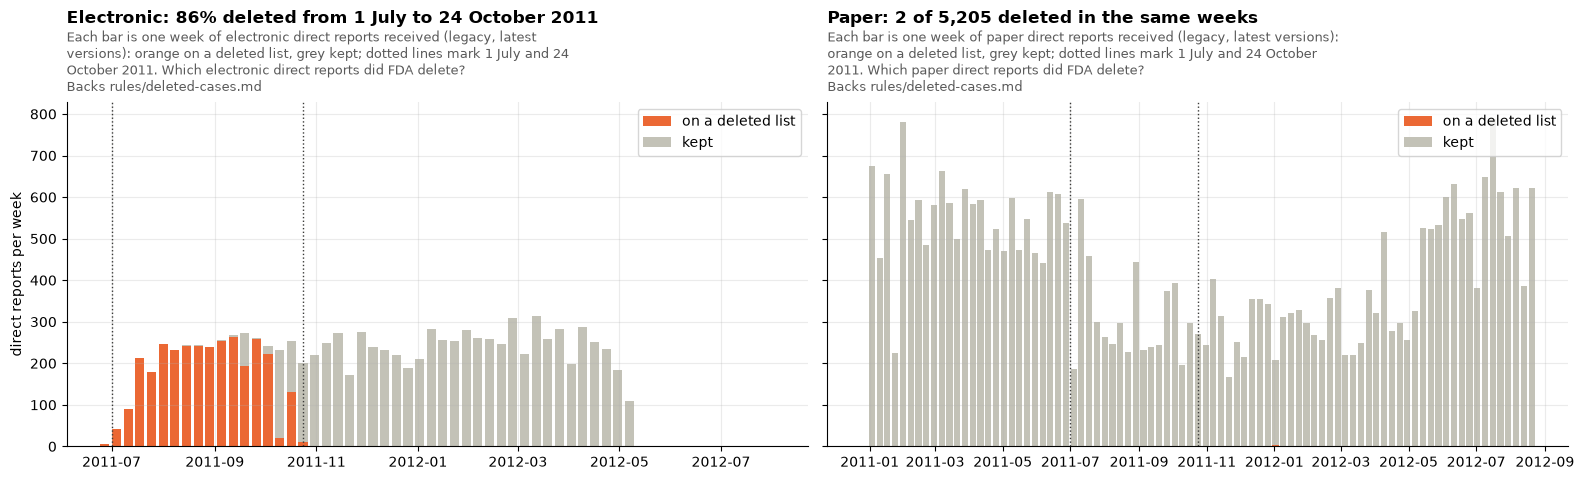

First electronic direct report in AERS: received 20110701.
Electronic direct reports received 2011-07-01 to 2011-10-24: 3,087 of 3,593 on a list (86%). Received after: 7 of 6,907.
Paper direct reports received in the same weeks: 2 of 5,205. Before 1 July 2011: 8 of 14,139.
Of the 3,087 deleted electronic reports in those weeks, 0 have no drug and 0 no reaction.


In [19]:
W0, W1 = "2011-07-01", "2011-10-24"
first_e = one(
    "SELECT min(fda_dt) FROM demo WHERE era_T = 'legacy' AND rept_cod = 'DIR' AND e_sub = 'Y'"
)[0]
dr = q(f"""
SELECT e_sub, date_trunc('week', fda_dt_T) AS week_start,
       CASE WHEN fda_dt_T < DATE '{W0}' THEN 'before' WHEN fda_dt_T <= DATE '{W1}' THEN 'window' ELSE 'after' END period,
       count(*) n, count(*) FILTER (WHERE listed_T) n_del
FROM latest_b_T WHERE era_T = 'legacy' AND rept_cod = 'DIR' AND e_sub IN ('Y', 'N') AND fda_dt_T >= DATE '2011-01-01'
GROUP BY ALL ORDER BY ALL""")
per = dr.groupby(["e_sub", "period"])[["n", "n_del"]].sum()
empty = one(f"""SELECT count(*) FILTER (WHERE NOT EXISTS (SELECT 1 FROM drug_latest_T d WHERE d.era_T = l.era_T AND d.primaryid = l.primaryid AND d.quarter_T = l.quarter_T)),
                       count(*) FILTER (WHERE NOT EXISTS (SELECT 1 FROM reac_latest_T r WHERE r.era_T = l.era_T AND r.primaryid = l.primaryid AND r.quarter_T = l.quarter_T)),
                       count(*)
                FROM latest_b_T l WHERE era_T = 'legacy' AND rept_cod = 'DIR' AND e_sub = 'Y' AND listed_T
                  AND fda_dt_T BETWEEN DATE '{W0}' AND DATE '{W1}'""")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.9), sharey=True)
for ax, (es, what) in zip(axes, [("Y", "electronic"), ("N", "paper")], strict=True):
    d = dr[dr.e_sub == es].groupby("week_start")[["n", "n_del"]].sum()
    ax.bar(d.index, d.n_del, width=5.5, color=SERIES[1], label="on a deleted list")
    ax.bar(d.index, d.n - d.n_del, bottom=d.n_del, width=5.5, color=SERIES[7], label="kept")
    for x_ in (W0, W1):
        ax.axvline(pd.Timestamp(x_), color="#3a3a38", lw=1, ls=":")
    claim = (
        f"Electronic: {100 * per.loc[('Y', 'window'), 'n_del'] / per.loc[('Y', 'window'), 'n']:.0f}% deleted from 1 July to 24 October 2011"
        if es == "Y"
        else f"Paper: {int(per.loc[('N', 'window'), 'n_del'])} of {int(per.loc[('N', 'window'), 'n']):,} deleted in the same weeks"
    )
    title(
        ax,
        claim,
        f"Each bar is one week of {what} direct reports received (legacy, latest versions): orange on a deleted list, grey kept; "
        "dotted lines mark 1 July and 24 October 2011.",
        f"Which {what} direct reports did FDA delete?",
        backs="Backs rules/deleted-cases.md",
        width=81,
    )
    ax.legend(loc="upper right")
axes[0].set_ylabel("direct reports per week")
plt.tight_layout()
plt.show()


def fmt(es, p):
    return f"{int(per.loc[(es, p), 'n_del']):,} of {int(per.loc[(es, p), 'n']):,}"


print(f"First electronic direct report in AERS: received {first_e}.")
print(
    f"Electronic direct reports received {W0} to {W1}: {fmt('Y', 'window')} on a list "
    f"({100 * per.loc[('Y', 'window'), 'n_del'] / per.loc[('Y', 'window'), 'n']:.0f}%). Received after: {fmt('Y', 'after')}."
)
print(
    f"Paper direct reports received in the same weeks: {fmt('N', 'window')}. Before 1 July 2011: {fmt('N', 'before')}."
)
print(
    f"Of the {empty[2]:,} deleted electronic reports in those weeks, {empty[0]} have no drug and {empty[1]} no reaction."
)

Direct reports flagged `e_sub = 'Y'` first appear on 1 July 2011. Of the 3,593 FDA received from then to 24 October 2011, 3,087 (86%) are on a deleted list; of the about 6,900 received after, 7 are. Paper direct reports received in the same weeks: 2 of 5,205. That is why 2011Q3 tops the chart above.

A separate study of this batch found the deleted reports look ordinary. They are not copies of other reports, every one names a drug and a reaction, and they look like the same route's kept reports a few weeks later. Removing them switches off about as many disproportionality signals as removing a random batch of the same size. FDA has not said why it deleted them; the lists say only that it happened before 2019.

**The rule (`rules/deleted-cases.md`):** legacy cases on FDA's deleted lists leave the case set, as FAERS cases already do: 6,074 more cases out once gap B is fixed. They stay in `demo_T` and `demo_latest_T`, as the FAERS deleted cases do. We follow FDA's lists as they are, the 2011 batch included.

## 6. Gap C: what changes when reaction terms are compared in capitals?

Legacy AERS writes every reaction term in capitals (`DRUG INEFFECTIVE`); FAERS writes MedDRA's own spelling (`Drug ineffective`). Compared as written, as in the release before, a legacy case can match a FAERS case only where the FAERS report also happens to be in capitals, even with gaps A and B fixed. The explorer's reaction filter already ignores case, so only the duplicate flags are affected.

**The fix** (`rules/reaction-term-case.md`): `pt_norm_T` on `reac_latest_T` is `pt` in upper case, and the duplicate key compares it. FDA's `pt` stays as written.

### How does each era write reaction terms?

From FDA's files, every version. FAERS's usual spelling of a term is the one it writes most often; a few terms are capitals in MedDRA itself (`COVID-19`), so they do not count as written in capitals.

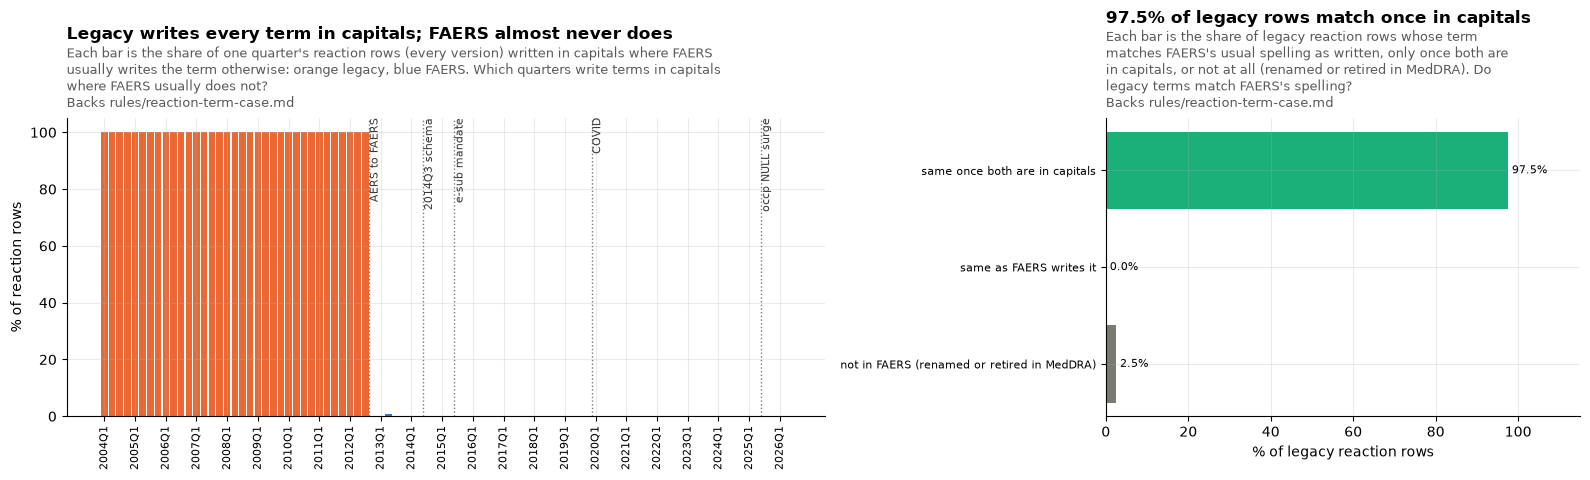

Legacy rows in capitals where FAERS's usual spelling is not: 100.0%. FAERS quarters with more than 0.1% such rows: 2012q4 (0.3%), 2013q1 (0.1%), 2013q2 (0.8%). Of 16,391 legacy terms, 3 are written as FAERS usually writes them and 14,841 match only once both are in capitals.


,terms,rows_,pct_of_rows
how,,,
same once both are in capitals,14841,15600177.0,97.5
same as FAERS writes it,3,10.0,0.0
not in FAERS (renamed or retired in MedDRA),1547,397114.0,2.5


In [20]:
con.execute("""CREATE OR REPLACE TEMP TABLE spelling_T AS
SELECT upper(pt) AS u, arg_max(pt, n) AS usual FROM (SELECT pt, count(*) n FROM reac WHERE era_T = 'faers' AND pt IS NOT NULL GROUP BY 1) GROUP BY 1""")
caps = q("""SELECT r.quarter_T, any_value(r.era_T) era_T, count(*) n,
                   100 * avg((r.pt = upper(r.pt) AND r.pt IS DISTINCT FROM s.usual)::INT) pct_caps
            FROM reac r LEFT JOIN spelling_T s ON s.u = upper(r.pt) WHERE r.pt IS NOT NULL GROUP BY 1 ORDER BY 1""")
terms = q("""
WITH t AS (SELECT pt, count(*) n FROM reac WHERE era_T = 'legacy' AND pt IS NOT NULL GROUP BY 1)
SELECT CASE WHEN s.usual = t.pt THEN 'same as FAERS writes it' WHEN s.usual IS NOT NULL THEN 'same once both are in capitals'
            ELSE 'not in FAERS (renamed or retired in MedDRA)' END how, count(*) terms, sum(n) rows_
FROM t LEFT JOIN spelling_T s ON s.u = upper(t.pt) GROUP BY 1 ORDER BY 1 DESC""").set_index("how")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.9), gridspec_kw={"width_ratios": [1.6, 1]})
a1.bar(range(len(caps)), caps.pct_caps, color=[ERA[e] for e in caps.era_T], width=0.85)
quarter_ticks(a1, caps.quarter_T)
mark_quarters(a1, caps.quarter_T)
a1.set_ylim(0, 105)
a1.set_ylabel("% of reaction rows")
title(
    a1,
    "Legacy writes every term in capitals; FAERS almost never does",
    "Each bar is the share of one quarter's reaction rows (every version) written in capitals where FAERS usually writes the term otherwise: "
    "orange legacy, blue FAERS.",
    "Which quarters write terms in capitals where FAERS usually does not?",
    backs="Backs rules/reaction-term-case.md",
    width=100,
)
share = 100 * terms.rows_ / terms.rows_.sum()
label_bars(
    a2,
    a2.barh(share.index[::-1], share.values[::-1], color=[SERIES[2], SERIES[1], SERIES[6]][::-1]),
    "{:.1f}%",
    horizontal=True,
)
a2.set_xlim(0, 115)
a2.set_xlabel("% of legacy reaction rows")
title(
    a2,
    f"{share['same once both are in capitals']:.1f}% of legacy rows match once in capitals",
    "Each bar is the share of legacy reaction rows whose term matches FAERS's usual spelling as written, only once both are in capitals, "
    "or not at all (renamed or retired in MedDRA).",
    "Do legacy terms match FAERS's spelling?",
    backs="Backs rules/reaction-term-case.md",
    width=62,
)
a2.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
f_caps = caps[(caps.era_T == "faers") & (caps.pct_caps > 0.1)]
leg = caps[caps.era_T == "legacy"]
print(
    f"Legacy rows in capitals where FAERS's usual spelling is not: {(leg.pct_caps * leg.n).sum() / leg.n.sum():.1f}%. "
    f"FAERS quarters with more than 0.1% such rows: {', '.join(f'{r.quarter_T} ({r.pct_caps:.1f}%)' for r in f_caps.itertuples())}. "
    f"Of {terms.terms.sum():,} legacy terms, {terms.terms.get('same as FAERS writes it', 0):,} are written as FAERS usually writes them and "
    f"{terms.terms.get('same once both are in capitals', 0):,} match only once both are in capitals."
)
terms.assign(pct_of_rows=share.round(1))

### What does it do to duplicates across the eras?

Counted here from the release before the fix, independently of the pipeline's code, with the reaction fingerprints built in section 2. With the terms as written, the fingerprint gives back the gap A key's groups exactly (checked below). Two rules from notebook 04: the AEOLUS rule, and the AEOLUS rule or the manufacturer case number (`mfr_num` with `mfr_sndr`, skipping number groups whose cases disagree on sex).

The first chart's bars add up: each includes every fix before it, so the third bar is gaps A, B and C with the deleted AERS cases removed, and the last bar, the release after, must equal it. The second chart shows gap C's own effect only: the change from gaps A and B to gaps A, B and C.

The release after equals gaps A, B and C with the deleted AERS cases removed: True


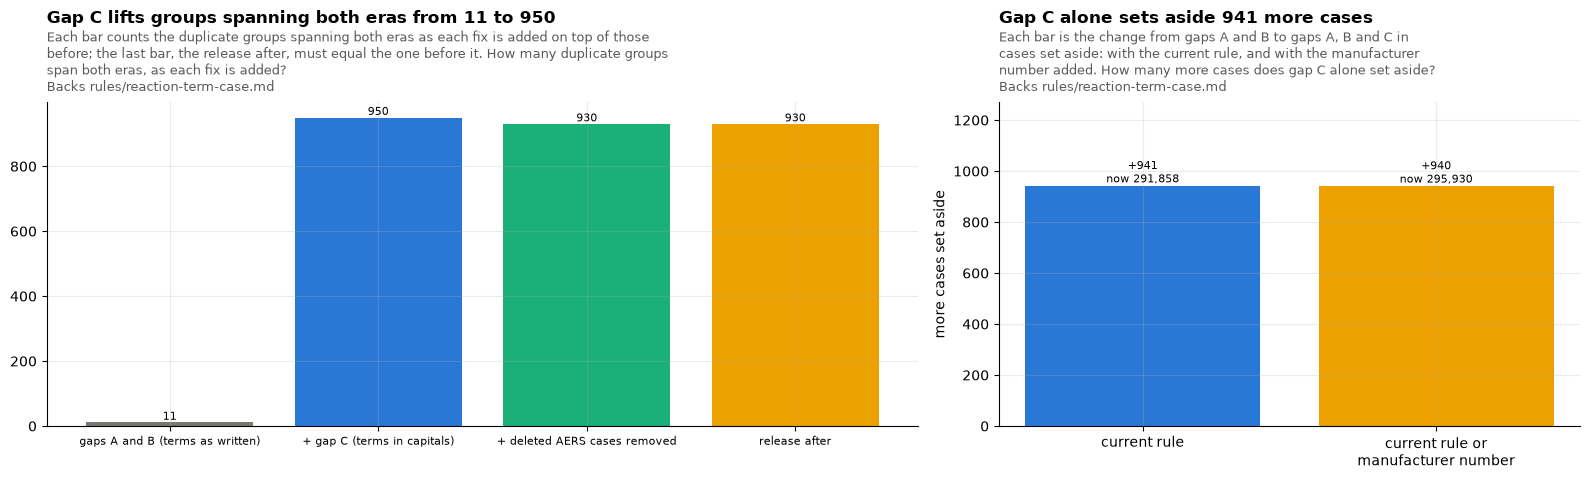

                                 groups_across_eras  set_aside_current_rule  set_aside_with_mfr_num
gaps A and B (terms as written)                  11                  290917                  294990
+ gap C (terms in capitals)                     950                  291858                  295930
+ deleted AERS cases removed                    930                  291764                  295811
release after                                   930                  291764                  295811


Cases set aside only once terms are compared in capitals:
  2 faers cases in a FAERS-only group
  879 faers cases in a group spanning both eras
  60 legacy cases in a group spanning both eras


,grp,era_T,case_key_T,received,event_dt,age,sex,country_T,reactions_as_fda_wrote_them
0,1,legacy,6778088,2008-10-03,20080313,75,F,FR,INTERSTITIAL LUNG DISEASE
1,1,faers,10020606,2014-03-19,20080313,75,F,FR,Interstitial lung disease
2,1,faers,10338600,2014-07-21,20080313,75,F,FR,Interstitial lung disease
3,2,legacy,7009065,2011-05-17,20021215,56,M,US,ANXIETY; DEPRESSION; INSOMNIA; MYOCARDIAL INFARCTION; MYOCARDIAL ISCHAEMIA
4,2,faers,10025243,2014-03-20,20021215,56,M,US,Anxiety; Depression; Insomnia; Myocardial infarction; Myocardial ischaemia
5,3,legacy,7913797,2011-04-12,20090518,76,F,US,BLINDNESS TRANSIENT; BLOOD PRESSURE INCREASED; DIZZINESS; MALAISE; VISUAL IMPAIRMENT
6,3,faers,10018925,2014-03-14,20090518,76,F,US,Blindness transient; Blood pressure increased; Dizziness; Malaise; Visual impairment


In [21]:
NOT_LISTED = "(SELECT * FROM grain_T WHERE NOT carried_T AND NOT legacy_listed_T)"
D = pd.DataFrame(
    {
        "gaps A and B (terms as written)": dup_counts(con, NOT_CARRIED, "iso_key_T"),
        "check: fingerprint, terms as written": dup_counts(con, NOT_CARRIED, "written_key_T"),
        "+ gap C (terms in capitals)": dup_counts(con, NOT_CARRIED, "up_key_T"),
        "+ deleted AERS cases removed": dup_counts(con, NOT_LISTED, "up_key_T"),
    }
).T
assert (D.iloc[0] == D.iloc[1]).all()  # the fingerprint reproduces the gap A key
acon.execute("""CREATE OR REPLACE TEMP TABLE built_T AS SELECT c.era_T, c.case_key_T, c.caseid, c.first_fda_dt_T, c.mfr_num, c.mfr_sndr,
                CASE WHEN upper(c.sex) IN ('F', 'M') THEN upper(c.sex) END AS sex_mf_T, k.dup_key_T
                FROM case_latest_T c JOIN case_dup_T k USING (era_T, case_key_T)""")
D.loc["release after"] = dup_counts(acon, "built_T", "dup_key_T")
D = D.drop(index="check: fingerprint, terms as written").astype(int)
print(
    "The release after equals gaps A, B and C with the deleted AERS cases removed:",
    bool((D.loc["release after"] == D.loc["+ deleted AERS cases removed"]).all()),
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.9), gridspec_kw={"width_ratios": [1.5, 1]})
label_bars(
    a1, a1.bar(D.index, D.groups_across_eras, color=[SERIES[6], SERIES[0], SERIES[2], SERIES[3]])
)
title(
    a1,
    f"Gap C lifts groups spanning both eras from {D.loc['gaps A and B (terms as written)', 'groups_across_eras']} to "
    f"{D.loc['+ gap C (terms in capitals)', 'groups_across_eras']}",
    "Each bar counts the duplicate groups spanning both eras as each fix is added on top of those before; the last bar, the release "
    "after, must equal the one before it.",
    "How many duplicate groups span both eras, as each fix is added?",
    backs="Backs rules/reaction-term-case.md",
    width=98,
)
a1.tick_params(axis="x", labelsize=8)
c_eff = D.loc["+ gap C (terms in capitals)"] - D.loc["gaps A and B (terms as written)"]
bars = a2.bar(
    ["current rule", "current rule or\nmanufacturer number"],
    [c_eff.set_aside_current_rule, c_eff.set_aside_with_mfr_num],
    color=[SERIES[0], SERIES[3]],
)
for b_, tot in zip(
    bars,
    [
        D.loc["+ gap C (terms in capitals)", "set_aside_current_rule"],
        D.loc["+ gap C (terms in capitals)", "set_aside_with_mfr_num"],
    ],
    strict=True,
):
    a2.text(
        b_.get_x() + b_.get_width() / 2,
        b_.get_height(),
        f"{b_.get_height():+,.0f}\nnow {tot:,}",
        ha="center",
        va="bottom",
        fontsize=8,
    )
a2.set_ylim(0, c_eff.max() * 1.35)
a2.set_ylabel("more cases set aside")
title(
    a2,
    f"Gap C alone sets aside {c_eff.set_aside_current_rule:,} more cases",
    "Each bar is the change from gaps A and B to gaps A, B and C in cases set aside: with the current rule, and with the manufacturer number added.",
    "How many more cases does gap C alone set aside?",
    backs="Backs rules/reaction-term-case.md",
    width=65,
)
plt.tight_layout()
plt.show()
print(D.to_string())
new = q(f"""WITH r AS (SELECT era_T, case_key_T, up_key_T,
               iso_key_T IS NOT NULL AND row_number() OVER (PARTITION BY iso_key_T ORDER BY {ORD}) > 1 AS before_,
               up_key_T IS NOT NULL AND row_number() OVER (PARTITION BY up_key_T ORDER BY {ORD}) > 1 AS after_,
               count(DISTINCT era_T) OVER (PARTITION BY up_key_T) AS eras FROM grain_T WHERE NOT carried_T)
            SELECT CASE WHEN eras = 2 THEN 'in a group spanning both eras' ELSE 'in a FAERS-only group' END AS where_, era_T, count(*) AS n
            FROM r WHERE after_ AND NOT before_ GROUP BY ALL ORDER BY ALL""")
print(
    "Cases set aside only once terms are compared in capitals:",
    *[f"{r.n:,} {r.era_T} cases {r.where_}" for r in new.itertuples()],
    sep="\n  ",
)
q("""WITH x AS (SELECT up_key_T FROM grain_T WHERE NOT carried_T AND up_key_T IS NOT NULL GROUP BY 1
               HAVING count(DISTINCT era_T) = 2 AND count(DISTINCT iso_key_T) > 1 ORDER BY min(case_key_T) LIMIT 3)
      SELECT dense_rank() OVER (ORDER BY up_key_T) AS grp, * EXCLUDE (up_key_T) FROM (
        SELECT g.up_key_T, g.era_T, g.case_key_T, strftime(g.first_fda_dt_T, '%Y-%m-%d') AS received, c.event_dt, c.age, c.sex, g.country_T,
               string_agg(r.pt, '; ' ORDER BY r.pt) AS reactions_as_fda_wrote_them
        FROM grain_T g JOIN x USING (up_key_T) JOIN case_latest_T c USING (era_T, case_key_T)
        JOIN reac_latest_T r ON r.era_T = c.era_T AND r.primaryid = c.primaryid AND r.quarter_T = c.quarter_T
        WHERE NOT g.carried_T GROUP BY ALL) ORDER BY grp, received""")

**What section 6 shows.** Legacy files write every reaction term in capitals. FAERS writes MedDRA's mixed case, except for under 1% of rows in its first three quarters (2012Q4 to 2013Q2). 14,841 of the 16,391 terms legacy used match FAERS's usual spelling once both are in capitals, covering 97.5% of legacy reaction rows. The other 1,547 terms (2.5% of rows) are not in FAERS at all, because MedDRA renamed or retired them; that is a question of MedDRA versions, not of letter case.

Compared in capitals, 950 duplicate groups span AERS and FAERS, against 11 with the terms as written, and 941 more cases are set aside: 879 FAERS and 60 legacy cases in groups spanning both eras, and 2 FAERS cases that match an early FAERS report written in capitals. Most FAERS cases set aside in these groups arrived years after the kept legacy case, under a new case number, as in the examples. With the manufacturer number added (notebook 04) the gain is the same, 940 more. Removing the deleted AERS cases then leaves 930 groups spanning both eras and 291,896 cases set aside, and the release after gives exactly that row.

## 7. How does each fix move the funnel?

The funnel counts cases at each step: every report version FDA published, the latest version of each case, what is left after FDA's deleted lists, and what is kept after duplicates are set aside. Each fix is added on top of the ones before it. The counts are made here from the release before the fixes, independently of the pipeline's code: gap B drops the AERS copy of every carried-over case; gap A rewrites the country inside each legacy duplicate key; gap C compares reaction terms in capitals (the key from section 2); the deleted AERS cases are then removed. Duplicates are regrouped each time with the release's own keep order.

**How to read the three panels.** One panel per step after the first (report versions never move). Each row adds one fix to the rows above it, so the rows add up. Each bar is the change from the release before these fixes: FDA publishes no deduplicated version to compare with. The label gives the change and the new total. The last row, the release after, must equal the row above it.

The release after equals the independent count with every fix and the deleted AERS cases removed: True


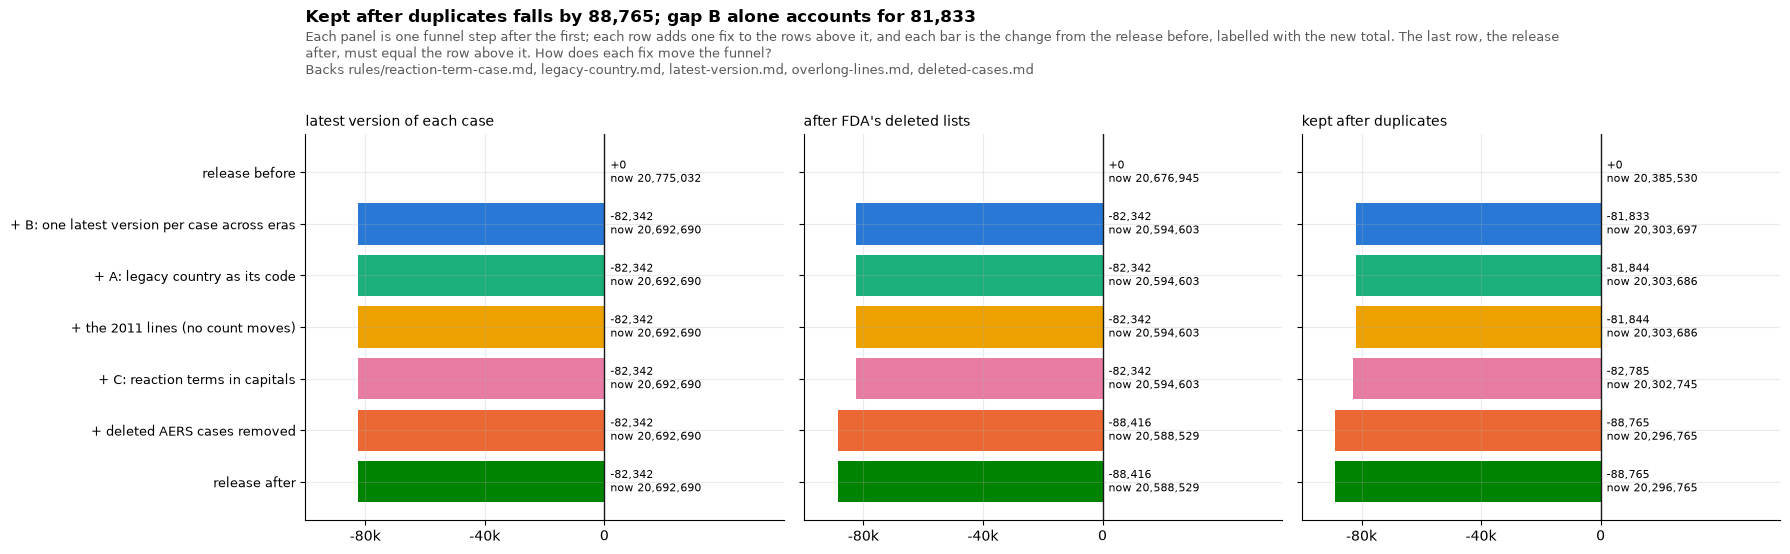

                    cases_out  already_set_aside  now_kept_legacy  now_kept_faers  kept_change
fix                                                                                           
gap B                   82342                395              114               0       -81833
deleted AERS cases       6074                 54               25              15        -5980


report versions latest version of each case            after FDA's deleted lists            kept after duplicates                       
                                                       total                       total       AERS                     total       AERS                 total       AERS       FAERS
scenario                                                                                                                                                                             
release before                                    24,812,425                  20,775,032  3,091,168                20,676,945  3,091,168            20,385,530  3,079,307  17,306,223
+ B: one latest version per case across eras      24,812,425                  20,692,690  3,008,826                20,594,603  3,008,826            20,303,697  2,997,474  17,306,223
+ A: legacy country as its code                   24,812,425                  20,692,690  3,008,826                20,594,603  3,008,826            20,303,686  2,997,472  17,306,214
+ the 2011 lines (no count moves)                 24,812,425                  20,692,690  3,008,826                20,594,603  3,008,826            20,303,686  2,997,472  17,306,214
+ C: reaction terms in capitals                   24,812,425                  20,692,690  3,008,826                20,594,603  3,008,826            20,302,745  2,997,412  17,305,333
+ deleted AERS cases removed                      24,812,425                  20,692,690  3,008,826                20,588,529  3,002,752            20,296,765  2,991,417  17,305,348
release after                                     24,812,425                  20,692,690  3,008,826                20,588,529  3,002,752            20,296,765  2,991,417  17,305,348

In [22]:
def kept(where, key):
    return dict(
        con.execute(f"""
    WITH s AS (SELECT * FROM grain_T WHERE {where}),
         r AS (SELECT era_T, {key} IS NULL OR row_number() OVER (PARTITION BY {key} ORDER BY {ORD}) = 1 AS kept FROM s)
    SELECT era_T, count(*) FILTER (WHERE kept) FROM r GROUP BY 1""").fetchall()
    )


def counts(where):
    return dict(
        con.execute(f"SELECT era_T, count(*) FROM grain_T WHERE {where} GROUP BY 1").fetchall()
    )


step = {s["id"]: s["count"] for s in BEFORE["steps"]}
versions = {e: step["report_versions"][e] for e in ("legacy", "faers")}
latest_before = {e: step["latest_versions"][e] for e in ("legacy", "faers")}
carried = one(
    "SELECT count(*) FROM demo_latest_T WHERE era_T = 'legacy' AND caseid IN (SELECT caseid FROM demo_latest_T WHERE era_T = 'faers')"
)[0]
latest_b = {"legacy": latest_before["legacy"] - carried, "faers": latest_before["faers"]}
B_, L_ = "NOT carried_T", "NOT carried_T AND NOT legacy_listed_T"
S = [
    ("release before", latest_before, counts("true"), kept("true", "dup_key_T")),
    ("+ B: one latest version per case across eras", latest_b, counts(B_), kept(B_, "dup_key_T")),
    ("+ A: legacy country as its code", latest_b, counts(B_), kept(B_, "iso_key_T")),
    ("+ the 2011 lines (no count moves)", latest_b, counts(B_), kept(B_, "iso_key_T")),
    ("+ C: reaction terms in capitals", latest_b, counts(B_), kept(B_, "up_key_T")),
    ("+ deleted AERS cases removed", latest_b, counts(L_), kept(L_, "up_key_T")),
]
ORDER = [
    "report versions",
    "latest version of each case",
    "after FDA's deleted lists",
    "kept after duplicates",
]
rows = []
for name, latest, after_del, kept_ in S:
    for st, c in zip(ORDER, [versions, latest, after_del, kept_], strict=True):
        rows.append(
            {"scenario": name, "step": st, "legacy": c.get("legacy", 0), "faers": c.get("faers", 0)}
        )
for s_, st in zip(BUILT["steps"], ORDER, strict=False):
    rows.append(
        {
            "scenario": "release after",
            "step": st,
            "legacy": s_["count"]["legacy"],
            "faers": s_["count"]["faers"],
        }
    )
F = pd.DataFrame(rows)
F["total"] = F.legacy + F.faers
wide = F.pivot(index="scenario", columns="step", values="total")[ORDER].reindex(F.scenario.unique())
same = bool(
    (
        F[F.scenario == "release after"].set_index("step")[["legacy", "faers"]]
        == F[F.scenario == "+ deleted AERS cases removed"].set_index("step")[["legacy", "faers"]]
    )
    .all()
    .all()
)
print(
    "The release after equals the independent count with every fix and the deleted AERS cases removed:",
    same,
)
sc = list(wide.index)
colors = [SERIES[6], SERIES[0], SERIES[2], SERIES[3], SERIES[4], SERIES[1], SERIES[5]]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharey=True)
for ax, st in zip(axes, ORDER[1:], strict=True):
    vals = wide.loc[sc, st] - wide.loc["release before", st]
    ax.barh(range(len(sc)), vals, color=colors)
    for i, (v, tot) in enumerate(zip(vals, wide.loc[sc, st], strict=True)):
        ax.text(2000, i, f"{v:+,}\nnow {tot:,}", va="center", ha="left", fontsize=8)
    ax.axvline(0, color="#1a1a19", lw=1)
    ax.set_xlim(-100000, 60000)
    ax.set_xticks([-80000, -40000, 0])
    ax.set_xticklabels(["-80k", "-40k", "0"])
    ax.set_title(st, loc="left", fontsize=10)
axes[0].set_yticks(range(len(sc)))
axes[0].set_yticklabels(sc, fontsize=9)
axes[0].invert_yaxis()
plt.tight_layout(rect=(0, 0, 1, 0.82))
left, right = axes[0].get_position().x0, axes[-1].get_position().x1
head = fig.add_axes([left, 0.845, right - left, 0.001])
head.axis("off")  # the figure's title sits on this empty strip
kept_all = wide.loc["release after", ORDER[3]] - wide.loc["release before", ORDER[3]]
kept_b = wide.loc[sc[1], ORDER[3]] - wide.loc["release before", ORDER[3]]
title(
    head,
    f"Kept after duplicates falls by {-kept_all:,}; gap B alone accounts for {-kept_b:,}",
    "Each panel is one funnel step after the first; each row adds one fix to the rows above it, and each bar is the change from the release "
    "before, labelled with the new total. The last row, the release after, must equal the row above it.",
    "How does each fix move the funnel?",
    backs="Backs rules/reaction-term-case.md, legacy-country.md, latest-version.md, overlong-lines.md, deleted-cases.md",
    width=200,
)
plt.show()


def kept_sql(where, key):
    return f"SELECT era_T, case_key_T, {key} IS NULL OR row_number() OVER (PARTITION BY {key} ORDER BY {ORD}) = 1 AS kept FROM grain_T WHERE {where}"


def leaving(fix, where0, key0, where1, key1):
    """Cases a fix takes out, how many of them were already set aside, and how many cases they had set aside become kept."""
    return q(f"""WITH a AS ({kept_sql(where0, key0)}), b AS ({kept_sql(where1, key1)})
      SELECT '{fix}' AS fix, count(*) FILTER (WHERE b.kept IS NULL) AS cases_out,
             count(*) FILTER (WHERE b.kept IS NULL AND NOT a.kept) AS already_set_aside,
             count(*) FILTER (WHERE b.kept AND NOT a.kept AND a.era_T = 'legacy') AS now_kept_legacy,
             count(*) FILTER (WHERE b.kept AND NOT a.kept AND a.era_T = 'faers') AS now_kept_faers
      FROM a LEFT JOIN b USING (era_T, case_key_T)""")


lv = pd.concat(
    [
        leaving("gap B", "true", "dup_key_T", B_, "dup_key_T"),
        leaving("deleted AERS cases", B_, "up_key_T", L_, "up_key_T"),
    ]
).set_index("fix")
lv["kept_change"] = -(lv.cases_out - lv.already_set_aside) + lv.now_kept_legacy + lv.now_kept_faers
print(lv.to_string())
eras_move = {
    st: [e for e in ("legacy", "faers") if F[F.step == st][e].nunique() > 1] for st in ORDER
}
cols = {}
for st in ORDER:
    d = F[F.step == st].set_index("scenario")
    cols[(st, "total")] = d.total
    for e in eras_move[st]:
        cols[(st, {"legacy": "AERS", "faers": "FAERS"}[e])] = d[e]
table = pd.DataFrame(cols).reindex(F.scenario.unique())
table.map(lambda v: f"{v:,}")

Gap B is nearly all of the movement: 82,342 cases stop being counted twice. Under it, kept falls by 81,833, not 82,342: 395 of the AERS copies were already set aside as duplicates, so removing them changes nothing kept, and 114 cases that had been set aside as duplicates of an AERS copy become kept once the copy leaves (82,342 less 395 less 114). Gap A moves a handful of duplicate flags and changes what the country filter finds. Gap C sets aside 941 more cases, almost all of them FAERS reports of an event a legacy report already holds. The 2011 lines put three drugs back and move no count.

Removing the deleted AERS cases works the same way: 6,074 cases leave; 54 of them were already set aside, and 40 cases they had set aside become kept (25 AERS, 15 FAERS), so kept falls by 5,980 (6,074 less 54 less 40). The table shows totals, and AERS and FAERS separately only where they move. The parity test (`tests/faers/test_parity.py`) expects these numbers.

## The rules this notebook backs

1. **Gap C, reaction terms compared in capitals** (`rules/reaction-term-case.md`).
2. **Gap A, the legacy country table** (`rules/legacy-country.md`, 208 rows), including `European Union` as `EU` and `FRANCE, METROPOLITAN` as `FX`. `SERBIA AND MONTENEGRO` stays `CS`.
3. **Gap B, one latest version per case across eras** (`rules/latest-version.md`).
4. **The 2011 run-on lines** (`rules/overlong-lines.md`).
5. **The 2012Q1 DEMO line with `$` in `mfr_num`** (case 8401177): kept as read and recorded in the manifest.
6. **Legacy cases on FDA's deleted lists** (`rules/deleted-cases.md`): removed from the case set, as FAERS cases already are: 6,074 more cases out after gap B. They stay in `demo_T` and `demo_latest_T`, as the FAERS deleted cases do.

## Methods-page cards from this notebook

The three cards behind the funnel steps these rules changed that remove cases, computed by the same functions the release build calls (`src/open_altio/faers/insights/cards`), on the release after. Each is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT`) for checking; the release carries them in `methods.json`.

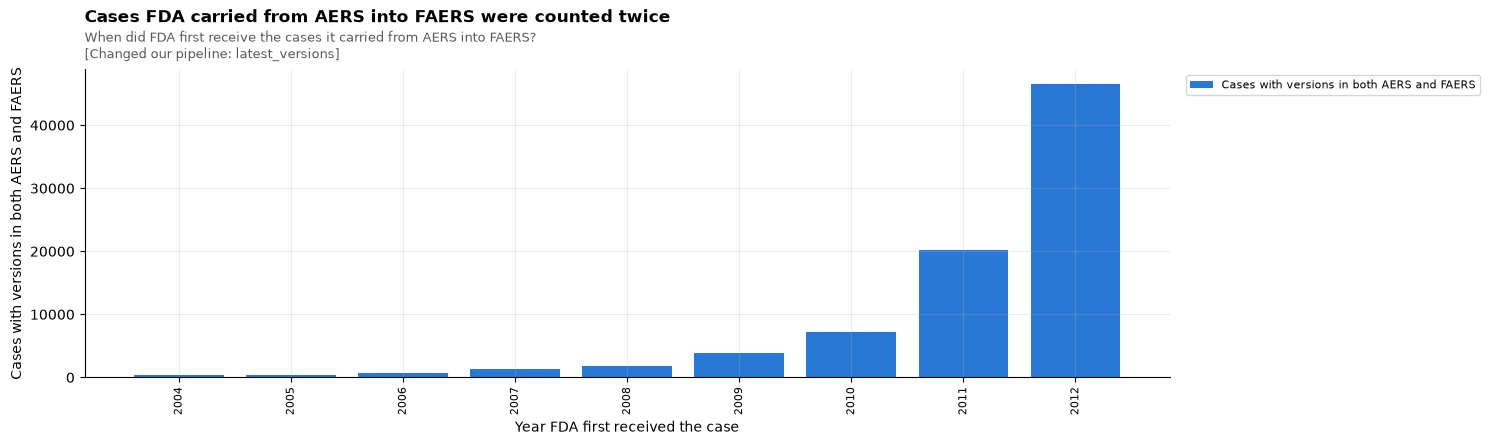

When FAERS began, FDA carried 82,342 AERS cases into it under the same case number, so taking the latest version within each era counted every one of them twice. We now take one latest version per case across both eras, which for these cases is always the FAERS one, so each counts once.


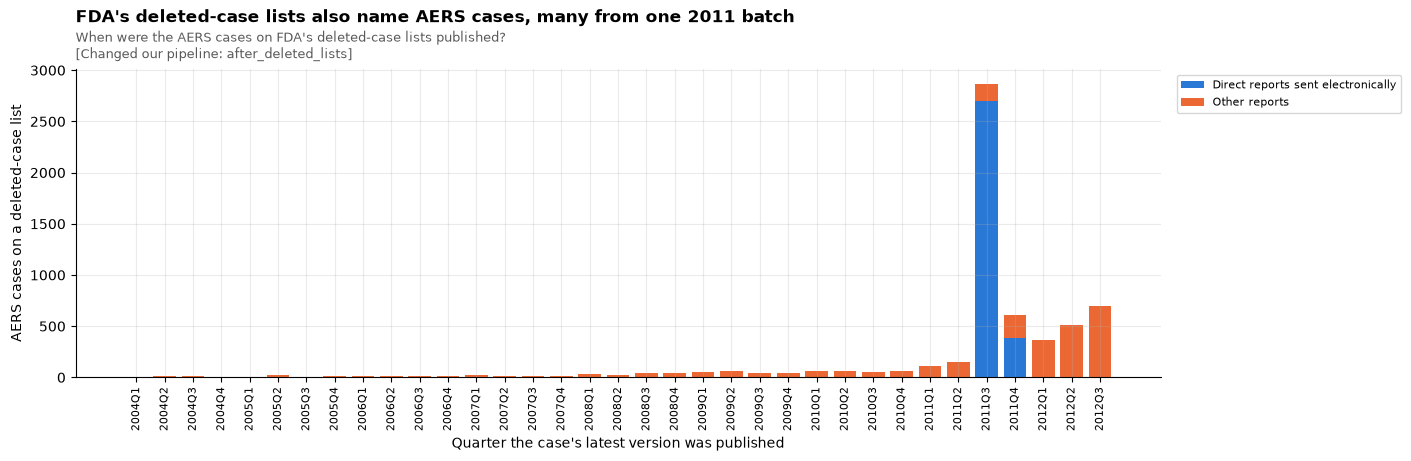

FDA's deleted-case lists also name 6,074 AERS cases, and 3,094 of them (51%) are direct reports sent to FDA electronically, 2,700 of those published in 2011Q3. We now take every listed AERS case out of the analysis set, as we already did for listed FAERS cases, and follow FDA's lists as they are.


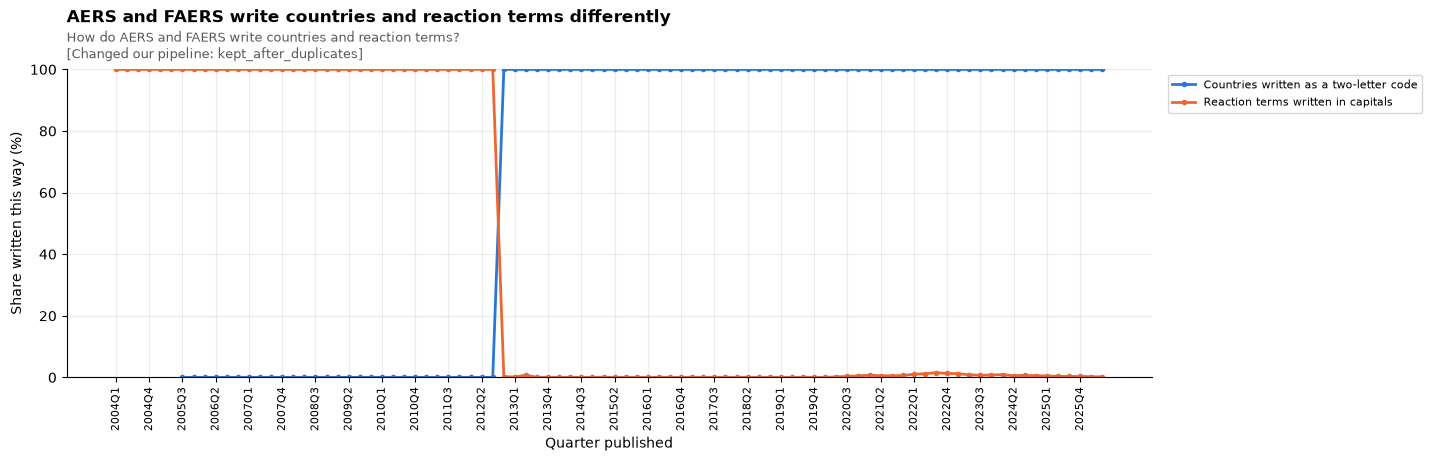

AERS wrote the country as a name (UNITED STATES) and every reaction term in capitals, while FAERS writes a two-letter code (US) and MedDRA's mixed case, so the same event reported in both could never be matched as a duplicate. Comparing countries as codes and terms in capitals, we now find 930 duplicate groups that span both eras; each shows its latest copy, the FAERS one in 57 of them, dated when FDA first received the earlier AERS report.
out/cards/02_case_versions.json


In [23]:
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import plot_card, write_cards

cards = compute_cards(
    acon,
    [
        "carried_cases_counted_twice",
        "deleted_lists_name_aers_cases",
        "eras_write_countries_and_terms_differently",
    ],
)
for card in cards:
    plot_card(card)
print(write_cards(cards, "02_case_versions"))